# Training statistics of the runs: figures from the Weights & Biases exports

> The figures and the spike table as they are in the thesis working copy of 11 Oct 2026, with the earlier arm labels, come from the copy `wandb_figures_before.ipynb`, which writes them to `assets/thesis_before/`.

This notebook is the source of every thesis figure, and of the one table, that is built from statistics the runs log at every training step. It reads two inputs:

- the Weights & Biases (W&B) exports under `assets/results/wandb/`, one CSV per metric with one column per run (`<run> - <metric>`, plus `__MIN` and `__MAX`);
- the Megatron training logs under `logs/`, which stand in where an export is missing and against which every export is checked.

It also reads the probe grid under `assets/results/phi-gap/` and the WikiText perplexities under `assets/results/eval/`, but only to compare the training statistics with them. For one figure it reads `assets/results/revival-probes/`, a summary of the probe dumps of the race from step 150 written by `scripts/summarize_revival_probes.py`. Every probe-based figure and table comes from `phi_gap_trajectories.ipynb`.

**What the thesis takes from here.** Everything is written to `assets/thesis/`. Set `THESIS_DIR` to the thesis folder to copy the files into its `figures/` and `tables/` as well.

| file | what it holds |
|---|---|
| `figures/fig_app_training_dynamics.pdf` | loss, MaxVio and dead experts of the 14 arms at every training step |
| `figures/fig_app_spike_anatomy.pdf` | every loss spike, aligned at its onset |
| `tables/tab_app_spikes.tex` | rows of the spike table, one per spike |
| `figures/fig_app_online_swapgap.pdf` | the logged swap gap and assignment potential of the 14 arms over training |
| `figures/fig_ex_swapgap.pdf` | the same without the assignment potential: the logged swap gap of the 14 arms (main text) |
| `figures/fig_app_online_swapgap_zero.pdf` | optional: the swap gap at zero price of the two bias arms (the thesis does not read it yet) |
| `figures/fig_app_collapse_induction.pdf` | the two collapse inductions |
| `figures/fig_step125_race.pdf` | the race from step 125 of the negative-auxiliary-loss induction, seven arms |
| `figures/fig_step125_variants.pdf` | its three variants, each against its base arm |
| `figures/fig_zloss_race.pdf` | the race from the negative z-loss checkpoint, with the softmax-carrier runs |
| `figures/fig_app_revival_probes.pdf` | how the bias arms and a loss arm revive the dead experts in the race from step 150: selections and gate weight from its probe dumps, dead experts and loss from its logs |

The thesis keeps its own figure and table environments and reads these files by name, so the notebook names no section, figure or table number of the thesis. The numbers the running text quotes, including every entry of the hand-written race tables, are collected with `note()` and printed together in the last cell.

**How to run.** From the repository root:

```bash
jupyter nbconvert --to notebook --execute --inplace notebooks/wandb_figures.ipynb
THESIS_DIR=~/thesis jupyter nbconvert --to notebook --execute --inplace notebooks/wandb_figures.ipynb   # also copy into the thesis
WANDB_FIGURES=fig_step125_race,tab_app_spikes jupyter nbconvert --to notebook --execute --inplace notebooks/wandb_figures.ipynb
```

`FIGURES` in the next cell (or the environment variable `WANDB_FIGURES`, a comma-separated list) chooses which files are drawn and written. Every number is computed and printed either way. Colours, dashes and labels come from `notebooks/arm_style.py`, which the probe notebook imports too, so an arm looks the same in every figure of the thesis.

## Terms

- **Arm:** one training run with one balancing recipe. The **fleet** is the 14 arms of the recipe comparison, 5500 steps each.
- **Training-batch statistic:** a value the run logs at every step on its own training batch. MaxVio, the dead experts, the swap gap and the assignment potential are computed per micro batch of 4 × 2048 = 8,192 tokens and per MoE layer, and averaged over the 8 MoE layers and all micro batches of the step: 256 in the fleet (global batch 1024), 32 in the races (global batch 128). The loss is the language-modeling loss of the step.
- **Probe statistic:** a value computed offline on a fixed held-out probe unit of 16,384 tokens. The two populations differ in size, content and mode (training against evaluation), so a probe number and a training-batch number are never read as one quantity.
- **Late window:** for training-batch statistics, steps 5001 to 5500, the 500 steps of the learning-rate anneal; for the probes, the 21 probe steps 5000, 5025, ..., 5500.
- **Induction:** a short run that collapses the router on purpose. A **race** restarts every arm from one collapsed checkpoint, with the same seed and batches.

## Rules for every number in this notebook

1. **One source per series.** A series comes from its W&B export when the export has it and the export passes the check against the logs below, and from the training log otherwise. The two are never spliced within one series.
2. **What a log line holds.** Megatron prints one line every `log_interval` steps (10, or 1 for the price-barrier arm and the race from step 125). The loss fields on a line are means over the steps since the previous line; the first line of a job holds its first step only and does not restart the mean, so the second line covers all steps from the job's first. Every other field is the value of the printed step itself, printed with two decimals (the gradient norm with three). The check below confirms this at every logged step.
3. **The export named `induce_sigmoid` holds the softmax induction.** Both negative z-loss inductions used the W&B run id `collapse`, the sigmoid one ran second, and W&B rejected every step it logged. So the sigmoid induction is read from its log only. Which source each induction uses is one entry of `INDUCTIONS` in the sources cell, and the check below tests that entry against the logs.
4. **A race number is computed on the raw per-step series.** The log-binned curves of the race figures are a display device only.

In [1]:
# CONFIG. Which files to draw and write: "all", or a list of names from the table above (without the
# extension), e.g. FIGURES = ["fig_step125_race", "tab_app_spikes"]. Every number is computed either way.
FIGURES = "all"
# fig_zloss_race: True adds a third panel with the softmax-carrier runs; False draws the ten race arms only.
ZLOSS_CARRIER_PANEL = True
# fig_step125_race, the race from step 125 (function fig_step125_race in the section of that race):
#   RACE_XSCALE  the step axis: "sqrt" (square root), "log" or "linear".
#   RACE_BINS    how each curve is averaged before drawing: "fixed" = means over bins of RACE_BIN steps;
#                "log" = single steps up to step 20, then bins of about 5 % of the step, and the loss panel
#                additionally as a centred 15-step mean first (the earlier figure).
#   RACE_XTICKS  the labelled steps, or None for the default of the scale.
# The earlier stacked figure is RACE_XSCALE = "log" with RACE_BINS = "log"; the thesis caption has to name the
# same axis and averaging. Every number is computed on the raw per-step series, whatever is chosen here.
RACE_XSCALE = "sqrt"
RACE_BINS = "fixed"
RACE_BIN = 10
RACE_XTICKS = None
# fig_step125_variants: each panel holds one base arm, its variant and the control. The base arm is drawn in its
# own colour, the variant in VARIANT_COLOR, which no arm uses. Set VARIANT_COLOR = None for the variant in its base
# arm's colour, VARIANT_DASH = ":" for the earlier dotted variant, and VARIANT_BASE_DASH = None to keep the base
# arm's own dash (dash-dot for the price-barrier bias).
VARIANT_COLOR = "#d6338a"
VARIANT_DASH = "-"
VARIANT_BASE_DASH = "-"

# The same choice from the command line, without editing this cell: WANDB_FIGURES=name,name jupyter nbconvert ...
import os  # noqa: E402

if os.environ.get("WANDB_FIGURES"):
    FIGURES = [name.strip() for name in os.environ["WANDB_FIGURES"].split(",") if name.strip()]
if os.environ.get("WANDB_RACE_XSCALE"):
    RACE_XSCALE = os.environ["WANDB_RACE_XSCALE"]
if os.environ.get("WANDB_RACE_BINS"):
    RACE_BINS = os.environ["WANDB_RACE_BINS"]

In [2]:
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, NullFormatter, NullLocator


def repo_root():
    """Find the checkout from the kernel's cwd, which differs between VS Code and nbconvert."""
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "assets" / "results" / "MANIFEST.csv").is_file():
            return base
    raise FileNotFoundError("no checkout above cwd holds assets/results/MANIFEST.csv")


ROOT = repo_root()
WANDB_DIR = ROOT / "assets" / "results" / "wandb"
LOG_DIR = ROOT / "logs"
PHI_GAP_DIR = ROOT / "assets" / "results" / "phi-gap"
# A summary of the probe dumps of the race from step 150 (scripts/summarize_revival_probes.py; the dumps themselves
# are not in the repository).
REVIVAL_PROBES = ROOT / "assets" / "results" / "revival-probes" / "race-step150_revival-probes.csv"
EVAL_DIR = ROOT / "assets" / "results" / "eval"
# What the thesis reads: the figures as PDF and the rows of its spike table as LaTeX. With THESIS_DIR
# set, every file is also copied into that folder's figures/ and tables/.
OUT_DIR = ROOT / "assets" / "thesis"
THESIS_DIR = Path(os.environ["THESIS_DIR"]).expanduser() if os.environ.get("THESIS_DIR") else None

# Colours, dashes, labels and scopes of the arms, shared with the probe notebook. The race-only arms
# (variants, softmax carriers, the softplus barrier at the global-batch scope) are in its appended section.
sys.path.insert(0, str(ROOT / "notebooks"))
from arm_style import (  # noqa: E402
    ARM_META,
    ARM_TABLE,
    BIAS_ARMS,
    GRAY,
    GRID_INK,
    HARD_GLOBAL,
    INK,
    INK_2,
    LEAD_HARD,
    MUTED,
    RACE_BASE,
    SCOPE_TITLES,
    SOFT_GLOBAL,
    SOFT_MICRO,
    apply_style,
    meta,
    race_meta,
)

FLEET_ARMS = [row[0] for row in ARM_TABLE]  # the 14 arms, in the legend order of the thesis figures
OUTPUTS = (
    "fig_app_training_dynamics",
    "fig_app_spike_anatomy",
    "tab_app_spikes",
    "fig_app_online_swapgap",
    "fig_ex_swapgap",
    "fig_app_online_swapgap_zero",
    "fig_app_collapse_induction",
    "fig_step125_race",
    "fig_step125_variants",
    "fig_zloss_race",
    "fig_app_revival_probes",
)
if FIGURES != "all":
    unknown = sorted(set(FIGURES) - set(OUTPUTS))
    assert not unknown, f"not an output of this notebook: {unknown}; choose from {OUTPUTS}"


def wanted(name):
    """Whether the CONFIG cell asks for this output file."""
    assert name in OUTPUTS, name
    return FIGURES == "all" or name in FIGURES


# Output helpers. Every file the thesis reads goes through write_rows or save_figure, and every number
# its text quotes goes through note, so the last cell can print them in one place.
NUMBERS = {}
WRITTEN = []


def note(section, name, value):
    NUMBERS.setdefault(section, {})[name] = value


def _targets(sub, name):
    bases = [OUT_DIR] + ([THESIS_DIR] if THESIS_DIR else [])
    paths = [base / sub / name for base in bases]
    for path in paths:
        path.parent.mkdir(parents=True, exist_ok=True)
    return paths


def write_rows(name, lines):
    """LaTeX rows of one thesis table, read there with \\importrows{name} (header.tex of the thesis)."""
    text = (
        "% generated by notebooks/wandb_figures.ipynb; do not edit by hand\n"
        + "\n".join(lines)
        + "\n"
    )
    for path in _targets("tables", f"{name}.tex"):
        path.write_text(text)
    WRITTEN.append(f"tables/{name}.tex")
    print(f"wrote tables/{name}.tex, {len(lines)} lines")


def save_figure(fig, name):
    for path in _targets("figures", f"{name}.pdf"):
        fig.savefig(path, metadata={"CreationDate": None})  # same data, same file
    WRITTEN.append(f"figures/{name}.pdf")


def spearman(a, b):
    """Spearman rank correlation of two series over their common index (ties get the average rank)."""
    a, b = pd.Series(a), pd.Series(b)
    common = a.index.intersection(b.index)
    return a.loc[common].rank().corr(b.loc[common].rank())


def table_label(arm):
    """The arm's name in a table row: the scope folded in and without the dagger that marks the sigmoid arms."""
    m = race_meta(arm)
    return m["table"].replace("$^{\\dagger}$", "") + (
        " (global)" if arm in ARM_META and arm.endswith("_global") else ""
    )


# The style of the thesis figures (notebooks/arm_style.py); the figures shown here are the ones the thesis prints.
apply_style()
print("checkout:", ROOT)
print("outputs:", "all" if FIGURES == "all" else ", ".join(FIGURES))

checkout: /home/claude/job29/moe-congestion-routing
outputs: all


---
## Sources

Every input is named once, in the next cell, and nowhere else. Its entries are:

- **`EXPORT_METRICS`:** what each export file holds, by the suffix of its name (`wandb_11B_lm_loss.csv` → `lm_loss`), with the metric name inside its column headers and the field of the training log that prints the same quantity.
- **`FLEET_LOG_JOBS`:** the training logs of the fleet arms, in run order (a resumed run is a second job). Five arms have no log in the repository: ALF-LB, the control, and the micro-batch linear hard, quadratic hard and quadratic soft arms. Their exports cannot be checked against a log.
- **`INDUCTIONS`:** the one source of each collapse induction.
- **`EXPORT_HOLDS`:** what an export holds where its name says otherwise. The check section tests every entry.
- **`STEP125_RUNS`, `ZLOSS_RUNS`, `STEP150_JOBS`:** the arms of the three races. The W&B group of a race run carries no information (it is the arm folder, or a variable left over in the shell), so the arms are named by their run, and the check section confirms each run against the log with the same run name.

The price-barrier arm of the fleet is in none of the 11B exports. The loader notices every fleet arm missing from an export and reads it from its training log, which must then print every step. It does so for this arm, from its two jobs (steps 1 to 4000, and 4001 to 5500 after a resume).

In [3]:
# Export files by the suffix of their name -> (metric name in the column headers, field of the training log).
EXPORT_METRICS = {
    "lm_loss": ("lm loss", "lm loss"),
    "maxvio": ("maxvio", "maxvio"),
    "dead_experts": ("dead_experts", "dead_experts"),
    "grad_norm": ("grad-norm", "grad norm"),
    "swapgap_linear": ("swapgap_linear", "swapgap_linear"),
    "swapgap_quadratic": ("swapgap_quadratic", "swapgap_quadratic"),
    "swapgap_zero": ("swapgap_zero", "swapgap_zero"),
    "phicong_linear": ("phi_cong_linear", "phi_cong_linear"),
    "phicong_quadratic": ("phi_cong_quadratic", "phi_cong_quadratic"),
    # every 500th step only; the logs print it on their own "validation loss at iteration" lines
    "lm_loss_val": ("lm loss validation", "lm loss validation"),
}
# The metrics logged at every training step (all but the validation loss).
STEP_METRICS = [key for key in EXPORT_METRICS if key != "lm_loss_val"]
# Log fields that are means over the steps since the previous line; every other field is the printed step's value.
LOG_MEAN_FIELDS = {
    "lm loss",
    "z_loss",
    "load_balancing_loss",
    "global_load_balancing_loss",
    "rosenthal_loss",
}

# The fleet: one export per metric, columns named by the arm's WANDB_NAMES entry in arm_style. Every other export in the
# same folder (e.g. wandb_11B_price_barrier_<metric>.csv for a run exported on its own) is merged into it; its
# columns may also be named by the W&B run name '<arm>-<experiment>'.
FLEET_EXPORT = "11B/wandb_11B"
FLEET_FOLDER = FLEET_EXPORT.split("/")[0]


def is_fleet(prefix):
    return prefix.split("/")[0] == FLEET_FOLDER


def fleet_arm(run):
    """The arm of a fleet export column: its W&B name, figure or table label, or a W&B run name '<arm>-<experiment>'."""
    for arm, m in ARM_META.items():
        if run in (m["wandb"], m["label"], m["table"].replace("$^{\\dagger}$", "")):
            return arm
    head = run.split("-")[0]
    return head if head in ARM_META else None


FINAL_STEP = 5500
FLEET_LOG_JOBS = {
    "rosenthal_quadratic_soft_global": ["3251444"],
    "rosenthal_linear_hard_global": ["3251449"],
    "rosenthal_quadratic_hard_global": ["3251454"],
    "switch": ["3264254"],
    "rosenthal_linear_soft": ["3265405"],
    "rosenthal_linear_soft_global": ["3265406"],
    "switch_global": ["3309236", "3318708"],
    "rosenthal_barrier_hard": ["3325982", "3328568"],
    "rosenthal_price_barrier": ["3345837", "3355934"],
}

# The collapse inductions, one source each. "wandb": the run in the export with this file prefix, which the
# check section must find equal to the log of `job`; "log": that job's training log, every 10th step.
INDUCTIONS = {
    "negative auxiliary loss": {
        "source": "wandb",
        "export": "collapse-induce/wandb_induce_negaux",
        "job": "3391576",
    },
    # The sigmoid negative z-loss induction, the start of the race from the negative z-loss checkpoint. Its W&B
    # history was rejected (run-id collision), so its log is the only source.
    "negative z-loss": {"source": "log", "job": "3315605"},
}
# What an export holds where its name says otherwise: file prefix -> the job whose log it must equal, and what that is.
EXPORT_HOLDS = {
    "collapse-induce/wandb_induce_sigmoid": {
        "job": "3309238",
        "holds": "negative z-loss induction with SOFTMAX scores (1000 steps), not the sigmoid one",
    },
}

# The race from step 125 of the negative-auxiliary-loss induction: W&B run -> arm. Seven canonical arms (all loss
# arms at the global-batch scope) and three variants, each of which changes one setting of a canonical arm.
STEP125_EXPORT = "recovery/wandb_step125"
STEP125_RUNS = {
    "switch-step125-switch": "switch_global",
    "rosenthal_linear_hard-step125-rosenthal-linear-hard": "rosenthal_linear_hard_global",
    "rosenthal_quadratic_hard-step125-rosenthal-quadratic-hard": "rosenthal_quadratic_hard_global",
    "rosenthal_barrier_hard-step125-rosenthal-barrier-hard": "rosenthal_barrier_hard_global",
    "alflb-step125-alflb": "alflb",
    "rosenthal_price_barrier-step125-rosenthal-price-barrier": "rosenthal_price_barrier",
    "control-step125-control": "control",
    "rosenthal_barrier_hard_coeff3e-2-step125-rosenthal-barrier-hard-coeff3e-2": "rosenthal_barrier_hard_global_coeff3e-2",
    "alflb_eta1e-2-step125-alflb-eta1e-2": "alflb_eta1e-2",
    "rosenthal_price_barrier_eta1e-2-step125-rosenthal-price-barrier-eta1e-2": "rosenthal_price_barrier_eta1e-2",
}
STEP125_VARIANTS = [
    "rosenthal_barrier_hard_global_coeff3e-2",
    "alflb_eta1e-2",
    "rosenthal_price_barrier_eta1e-2",
]
STEP125_CANONICAL = [arm for arm in STEP125_RUNS.values() if arm not in STEP125_VARIANTS]

# The race from step 500 of the negative z-loss induction: ten arms and three softmax-carrier runs, which compute
# the balancing loss on the softmax of the logits while the router selects on sigmoid scores.
ZLOSS_EXPORTS = ["recovery-null/wandb_recovery_null", "recovery-null/wandb_softmax_carrier"]
ZLOSS_RUNS = {
    "switch-recovery-switch": "switch_global",
    "rosenthal_linear_hard-recovery-rosenthal-linear-hard": "rosenthal_linear_hard_global",
    "rosenthal_linear_hard_micro-recovery-rosenthal-linear-hard-micro": "rosenthal_linear_hard_micro",
    "rosenthal_linear_soft-recovery-rosenthal-linear-soft": "rosenthal_linear_soft_global",
    "rosenthal_quadratic_hard-recovery-rosenthal-quadratic-hard": "rosenthal_quadratic_hard_global",
    "rosenthal_quadratic_soft-recovery-rosenthal-quadratic-soft": "rosenthal_quadratic_soft_global",
    "rosenthal_barrier_hard-recovery-rosenthal-barrier-hard": "rosenthal_barrier_hard_global",
    "rosenthal_barrier_soft-recovery-rosenthal-barrier-soft": "rosenthal_barrier_soft_global",
    "alflb-recovery-alflb": "alflb",
    "control-recovery-control": "control",
    "switch-carrier-switch": "switch_global_carrier",
    "switch-carrier-switch-z-1e-2": "switch_global_carrier_z1e-2",
    "rosenthal_barrier_hard-carrier-rosenthal-barrier-hard": "rosenthal_barrier_hard_global_carrier",
}
ZLOSS_CARRIERS = [
    "switch_global_carrier",
    "switch_global_carrier_z1e-2",
    "rosenthal_barrier_hard_global_carrier",
]
ZLOSS_ARMS = [arm for arm in ZLOSS_RUNS.values() if arm not in ZLOSS_CARRIERS]

# The race from the final, annealed step-150 checkpoint of the negative-auxiliary-loss induction: not exported, so
# read from its logs. Its price-barrier W&B id is shared by four jobs; only the rerun `-r2` (3393836) is clean.
STEP150_JOBS = {
    "3392692": "control",
    "3392693": "alflb",
    "3392695": "rosenthal_barrier_hard_global",
    "3393836": "rosenthal_price_barrier",
}

---
## Loaders

- **Exports:** `read_export(prefix)` turns every file `<prefix>_<metric>.csv` into one tidy frame with the columns run, metric, step and value. It refuses a column whose metric name is not the one the file name promises, and it records whether `__MIN` and `__MAX` equal the value, which they do when W&B has not bucketed steps.
- **Logs:** `parse_log` reads the resolved arguments, every iteration line and every validation line of one Megatron log. `LOG_INFO` has one row per log.
- **The fleet:** `FLEET[arm]` is a frame with one row per step 1..5500 and one column per metric. Each column comes from the export where the export has it, else from the arm's per-step training log.

In [4]:
EXPORT_CHECKS = []  # one row per export file, for the check section


def export_files(prefix):
    """The files <prefix>_<metric>.csv of one export, by metric."""
    folder, stem = prefix.rsplit("/", 1)
    files = {}
    for path in sorted((WANDB_DIR / folder).glob(f"{stem}_*.csv")):
        key = path.stem[len(stem) + 1 :]
        if key in EXPORT_METRICS:
            files[key] = path
    assert files, f"no export files {prefix}_<metric>.csv"
    return files


def read_export(prefix):
    """Every file of one export as one tidy frame: run, metric, step, value (empty steps dropped)."""
    frames = []
    for key, path in export_files(prefix).items():
        name = EXPORT_METRICS[key][0]
        wide = pd.read_csv(path)
        assert wide.Step.is_unique and (wide.Step == wide.Step.astype(int)).all(), path.name
        wide = wide.set_index("Step")
        columns = [c for c in wide.columns if not c.endswith(("__MIN", "__MAX"))]
        differ = 0
        for col in columns:
            run, metric = col.rsplit(" - ", 1)
            assert metric == name, f"{path.name}: column {col!r} does not hold {name!r}"
            for suffix in ("__MIN", "__MAX"):
                if col + suffix in wide:
                    other = wide[col + suffix]
                    differ += int(
                        not ((other == wide[col]) | (other.isna() & wide[col].isna())).all()
                    )
            values = wide[col].dropna().astype(float)
            frames.append(
                pd.DataFrame(
                    {
                        "run": run,
                        "metric": key,
                        "step": values.index.astype(int),
                        "value": values.values,
                    }
                )
            )
        EXPORT_CHECKS.append(
            {
                "file": f"{prefix}_{key}.csv",
                "runs": len(columns),
                "steps": f"{int(wide.index.min())}..{int(wide.index.max())}",
                "MIN/MAX columns that differ": differ,
            }
        )
    return pd.concat(frames, ignore_index=True)


def by_run(tidy):
    """{run: frame indexed by step, one column per metric}, in the order of the export's columns."""
    return {
        run: g.pivot(index="step", columns="metric", values="value").sort_index()
        for run, g in tidy.groupby("run", sort=False)
    }


# ---------------------------------------------------------------------------------------------------------
# Megatron logs.
ITERATION = re.compile(r"\biteration\s+(\d+)/\s*(\d+) \|(.*)$")
FIELD = re.compile(r"^\s*([^:|]+?)\s*:\s*([-+0-9.Ee]+|nan|inf|-inf)\s*$")
ARGUMENT = re.compile(r"^0:\s+(\w+) \.{2,} (.*)$")
VALIDATION = re.compile(
    r"validation loss at iteration\s+(\d+)( on validation set)? \| lm loss value: ([-+0-9.Ee]+)"
)
LOG_ARGS = (
    "wandb_exp_name",
    "log_interval",
    "train_iters",
    "world_size",
    "global_batch_size",
    "micro_batch_size",
    "seq_length",
    "seed",
    "moe_router_score_function",
    "moe_router_aux_score_function",
    "moe_router_load_balancing_type",
    "moe_aux_loss_coeff",
    "moe_z_loss_coeff",
    "moe_router_bias_update_rate",
)


def parse_log(path):
    """The first argument block, every iteration line (one row per printed step) and every validation line."""
    args, lines, validation, repeated = {}, {}, [], 0
    in_args, seen_args = False, False
    with open(path, errors="replace") as handle:
        for line in handle:
            if not seen_args or in_args:
                if line.startswith("0:") and "--- arguments ---" in line:
                    in_args = True
                    continue
                if in_args:
                    if "end of arguments" in line:
                        in_args, seen_args = False, True
                    else:
                        found = ARGUMENT.match(line.rstrip("\n"))
                        if found:
                            args.setdefault(found.group(1), found.group(2).strip())
                    continue
            found = ITERATION.search(line)
            if found and "consumed samples" in line:
                step = int(found.group(1))
                repeated += step in lines
                lines[step] = {
                    f.group(1).strip(): float(f.group(2))
                    for part in found.group(3).split("|")
                    if (f := FIELD.match(part))
                }
                continue
            found = VALIDATION.search(line)
            if found:
                validation.append(
                    {
                        "step": int(found.group(1)),
                        "final": bool(found.group(2)),
                        "lm loss": float(found.group(3)),
                    }
                )
    frame = pd.DataFrame.from_dict(lines, orient="index").sort_index()
    return args, frame, validation, repeated


LOG_LINES, LOG_VALIDATION, _info = {}, {}, []
for path in sorted(LOG_DIR.glob("*.log")):
    job = re.search(r"_(\d+)\.log$", path.name).group(1)
    args, frame, validation, repeated = parse_log(path)
    if not args:  # not a training job, or one that failed before Megatron printed its arguments
        continue
    LOG_LINES[job], LOG_VALIDATION[job] = frame, validation
    _info.append(
        {
            "job": job,
            "file": path.name,
            **{k: args.get(k) for k in LOG_ARGS},
            "lines": len(frame),
            "first": int(frame.index.min()) if len(frame) else None,
            "last": int(frame.index.max()) if len(frame) else None,
            "repeated lines": repeated,
        }
    )
LOG_INFO = pd.DataFrame(_info).set_index("job")
LOG_INFO["log_interval"] = LOG_INFO.log_interval.astype(int)
assert LOG_INFO.index.is_unique and not LOG_INFO["repeated lines"].any(), LOG_INFO[
    LOG_INFO["repeated lines"] > 0
]
print(f"{len(LOG_INFO)} logs, {int((LOG_INFO.lines > 0).sum())} with iteration lines")


def log_frame(jobs):
    """The printed lines of one run's jobs, in order; the jobs of a resumed run must not overlap."""
    frames = [LOG_LINES[job] for job in jobs]
    for before, after in zip(frames, frames[1:]):
        assert before.index.max() < after.index.min(), f"jobs {jobs} overlap"
    return pd.concat(frames)


def log_windows(jobs):
    """The steps a printed mean field covers, per printed step (rule 2): a job's first line holds its first step
    only and does not restart the mean, so its second line covers every step from the first."""
    windows = {}
    for job in jobs:
        steps = LOG_LINES[job].index.tolist()
        for i, step in enumerate(steps):
            windows[step] = (steps[0] if i <= 1 else steps[i - 1] + 1, step)
    return windows


def per_step_from_log(jobs, fields):
    """Per-step series of a run whose log prints every step. A mean field on a line that covers more than one step
    (the second line of each job) is turned back into the value of the printed step."""
    lines = log_frame(jobs)
    assert (LOG_INFO.loc[jobs, "log_interval"] == 1).all(), f"jobs {jobs} do not print every step"
    windows = log_windows(jobs)
    out = {}
    for field in fields:
        values = lines[field].copy()
        if field in LOG_MEAN_FIELDS:
            for step, (first, last) in windows.items():
                if first < last:
                    values.loc[step] = (last - first + 1) * values.loc[step] - values.loc[
                        first : last - 1
                    ].sum()
        out[field] = values
    return pd.DataFrame(out)


# ---------------------------------------------------------------------------------------------------------
# Every export in the W&B folder, so that the check section sees all of them, used or not.
EXPORTS = {}
for path in sorted(WANDB_DIR.glob("*/*.csv")):
    stem = next(
        (path.stem[: -len(key) - 1] for key in EXPORT_METRICS if path.stem.endswith("_" + key)),
        None,
    )
    assert stem is not None, f"{path.name}: no known metric suffix"
    prefix = f"{path.parent.name}/{stem}"
    if prefix not in EXPORTS:
        EXPORTS[prefix] = by_run(read_export(prefix))
print(f"{len(EXPORTS)} exports:", ", ".join(f"{p} ({len(r)} runs)" for p, r in EXPORTS.items()))

# ---------------------------------------------------------------------------------------------------------
# The fleet: the export where it has the arm and metric, else the arm's per-step log.
METRICS = STEP_METRICS  # the validation loss is checked and used on its own (check section)
fleet_runs = {}  # arm -> its exported metrics, merged over every export in the fleet folder
for prefix, runs in EXPORTS.items():
    if not is_fleet(prefix):
        continue
    for run, frame in runs.items():
        arm = fleet_arm(run)
        assert arm is not None, f"{prefix}: column {run!r} names no arm"
        if arm in fleet_runs:
            both = fleet_runs[arm].columns.intersection(frame.columns)
            assert all(
                np.allclose(
                    fleet_runs[arm][k].dropna(),
                    frame[k].reindex(fleet_runs[arm][k].dropna().index),
                    rtol=1e-9,
                )
                for k in both
            ), f"{arm} is in two fleet exports with different values"
            frame = fleet_runs[arm].combine_first(frame)
        fleet_runs[arm] = frame
FLEET, FLEET_SOURCE = {}, {}
for arm in FLEET_ARMS:
    exported = fleet_runs.get(arm, pd.DataFrame())
    from_log = [key for key in METRICS if key not in exported]
    columns = {
        key: exported[key].reindex(range(1, FINAL_STEP + 1)) for key in METRICS if key in exported
    }
    # Single steps an export lacks (the price-barrier run lost the last step of its first job, step 4000) are read
    # from the arm's logs, which then must print every step.
    holes = sorted({int(step) for key, col in columns.items() for step in col.index[col.isna()]})
    if from_log or holes:
        logged = per_step_from_log(FLEET_LOG_JOBS[arm], [EXPORT_METRICS[key][1] for key in METRICS])
        for key in from_log:
            columns[key] = logged[EXPORT_METRICS[key][1]]
        for key, col in columns.items():
            columns[key] = col.fillna(logged[EXPORT_METRICS[key][1]])
    frame = pd.DataFrame(columns)[METRICS]
    assert list(frame.index) == list(range(1, FINAL_STEP + 1)) and frame.notna().all().all(), (
        f"{arm}: steps missing"
    )
    FLEET[arm] = frame
    FLEET_SOURCE[arm] = (
        "W&B"
        if not from_log and not holes
        else f"log {'+'.join(FLEET_LOG_JOBS[arm])}"
        if len(from_log) == len(METRICS)
        else "W&B"
        + (f"; log for {', '.join(from_log)}" if from_log else "")
        + (
            f"; log for step{'s' if len(holes) > 1 else ''} {', '.join(map(str, holes))}, missing in the export"
            if holes
            else ""
        )
    )
print(pd.Series(FLEET_SOURCE, name="source").to_string())

58 logs, 51 with iteration lines


6 exports: 11B/wandb_11B (14 runs), collapse-induce/wandb_induce_negaux (1 runs), collapse-induce/wandb_induce_sigmoid (1 runs), recovery/wandb_step125 (10 runs), recovery-null/wandb_recovery_null (10 runs), recovery-null/wandb_softmax_carrier (3 runs)
switch                                                                       W&B
rosenthal_linear_hard                                                        W&B
rosenthal_linear_soft                                                        W&B
rosenthal_quadratic_hard                                                     W&B
rosenthal_quadratic_soft                                                     W&B
rosenthal_barrier_hard                                                       W&B
alflb                                                                        W&B
rosenthal_price_barrier            W&B; log for step 4000, missing in the export
switch_global                                                                W&B
rosenthal_linear_h

---
## Check: every export against the training logs, at every logged step

For each run of each export, the check takes the logs that should hold the same run: for the fleet, the jobs of `FLEET_LOG_JOBS`; for an export listed in `EXPORT_HOLDS`, the job given there; for every other run, the logs whose W&B run name (`wandb_exp_name`) equals the run's name. At every printed step of those logs it compares

- a mean field (the loss) with the mean of the export over the steps the line covers (rule 2 of the header), to a relative $2 \cdot 10^{-6}$ (the log prints seven significant digits);
- every other field with the export's value at the printed step, to half the last printed digit (0.005, and 0.0005 for the gradient norm).

A run passes when no compared line is off. When a run's own log fails, or it has none, every log of the repository is tried, so the table says which job the export really holds. A run whose name points to one job and whose values are those of another is **mislabelled**. The table also lists the logs whose run name equals the run's name, to make such a case visible.

Below the table: whether the `__MIN`/`__MAX` columns equal the values (no W&B bucketing), whether the dead-expert counts lie on the grid of $1/(8 \cdot \text{micro batches})$ that an average over the 8 layers and all micro batches of a step must lie on, and whether every race starts all its runs from one state.

In [5]:
REL_TOL_MEAN = 2e-6  # mean fields: seven significant digits in the log
ABS_TOL = {"grad norm": 0.00051}  # printed with three decimals
ABS_TOL_DEFAULT = 0.0051  # MoE metrics: printed with two decimals


def compare(frame, jobs):
    """Compare one exported run with the printed lines of `jobs`. Returns {log field: (lines, max deviation, lines off)};
    the deviation is relative for a mean field and absolute otherwise."""
    lines, windows = log_frame(jobs), log_windows(jobs)
    out = {}
    for key, (_, field) in EXPORT_METRICS.items():
        if key not in frame or field not in lines:
            continue
        series = frame[key]
        logged = lines[field].dropna()
        steps = logged.index.to_numpy()
        first = np.array([windows[s][0] if field in LOG_MEAN_FIELDS else s for s in steps])
        # window means from a cumulative sum over a gap-free step range; a window with a missing step is skipped
        lo, hi = (
            int(min(series.index.min(), first.min())),
            int(max(series.index.max(), steps.max())),
        )
        full = series.reindex(range(lo, hi + 1))
        filled = np.concatenate([[0.0], np.nan_to_num(full.to_numpy()).cumsum()])
        holes = np.concatenate([[0], full.isna().to_numpy().cumsum()])
        a, b = first - lo, steps - lo + 1
        complete = (holes[b] - holes[a] == 0) & (a >= 0)
        if not complete.any():
            continue
        # A single-step field is read directly: a cumulative sum would lose the small values next to the
        # gradient norms of 1e17 in the race from the negative z-loss checkpoint.
        reference = (
            (filled[b] - filled[a]) / (b - a)
            if field in LOG_MEAN_FIELDS
            else full.to_numpy()[np.clip(b - 1, 0, len(full) - 1)]
        )[complete]
        value = logged.to_numpy()[complete]
        if field in LOG_MEAN_FIELDS:
            deviation = np.abs(value - reference) / np.abs(reference)
            off = deviation > REL_TOL_MEAN
        else:
            deviation = np.abs(value - reference)
            off = deviation > ABS_TOL.get(field, ABS_TOL_DEFAULT) + 1e-9 * np.abs(reference)
        out[field] = (int(complete.sum()), float(deviation.max()), int(off.sum()))
    return out


def passes(result):
    """At least three lines compared on the loss or MaxVio, and none off. Three, because the arms of a race share
    their first step, so a single line cannot tell them apart."""
    compared = max(result.get("lm loss", (0,))[0], result.get("maxvio", (0,))[0]) if result else 0
    return compared >= 3 and all(off == 0 for _, _, off in result.values())


def summary(result):
    if not result:
        return "nothing to compare"
    loss = result.get("lm loss")
    rest = [v for f, v in result.items() if f != "lm loss"]
    parts = []
    if loss:
        parts.append(f"loss {loss[0]} lines, rel. dev. <= {loss[1]:.1e}")
    if rest:
        parts.append(f"{len(rest)} other fields, abs. dev. <= {max(v[1] for v in rest):.4f}")
    off = sum(v[2] for v in result.values())
    return "; ".join(parts) + (f"; {off} lines OFF" if off else "")


CANDIDATES = [job for job in LOG_INFO.index if LOG_INFO.lines[job] >= 5]
CHECK = []
for prefix, runs in EXPORTS.items():
    for run, frame in runs.items():
        if is_fleet(prefix):
            expected = FLEET_LOG_JOBS.get(fleet_arm(run), [])
        elif prefix in EXPORT_HOLDS:
            expected = [EXPORT_HOLDS[prefix]["job"]]
        else:
            expected = sorted(LOG_INFO.index[LOG_INFO.wandb_exp_name == run])
        by_name = sorted(LOG_INFO.index[(LOG_INFO.wandb_exp_name == run) & (LOG_INFO.lines > 0)])
        # A run continued in a second job is checked against both jobs at once; separate runs one by one.
        groups = [expected] if is_fleet(prefix) else [[job] for job in expected]
        own = {
            "+".join(g): compare(frame, g)
            for g in groups
            if g and all(LOG_INFO.lines[j] > 0 for j in g)
        }
        ok = [name for name, result in own.items() if passes(result)]
        found = ok
        if not ok:  # try every log of the repository
            found = [job for job in CANDIDATES if passes(compare(frame, [job]))]
        name_ok = [job for job in by_name if passes(compare(frame, [job]))]
        if ok and by_name and not name_ok:
            verdict = f"MISLABELLED: its name is the run of job {'+'.join(by_name)}, its values are job {'+'.join(ok)}"
        elif ok:
            verdict = "pass"
        elif found:
            verdict = f"FAIL against {'+'.join(expected) or 'no log'}; its values are job {'+'.join(found)}"
        elif not expected:
            verdict = "no log in the repository"
        else:
            verdict = "FAIL"
        CHECK.append(
            {
                "export": prefix,
                "run": run,
                "steps": f"{frame.index.min()}..{frame.index.max()}",
                "checked against": "+".join(expected) or "-",
                "result": "; ".join(f"{name}: {summary(result)}" for name, result in own.items())
                or "-",
                "logs with this run name": "+".join(by_name) or "-",
                "values are job": "+".join(found) or "-",
                "verdict": verdict,
            }
        )
CHECK = pd.DataFrame(CHECK)
with pd.option_context("display.max_colwidth", 70, "display.width", 250):
    print(CHECK[["export", "run", "steps", "checked against", "verdict"]].to_string(index=False))
counts = CHECK.verdict.str.split(":").str[0].str.split(" against").str[0].value_counts()
print("\n" + ", ".join(f"{v} {k}" for k, v in counts.items()))

                              export                                                                       run   steps checked against                                                                     verdict
                       11B/wandb_11B                           rosenthal_price_barrier-rosenthal-price-barrier 1..5500 3345837+3355934                                                                        pass
                       11B/wandb_11B                                                    softplus barrier, hard 1..5500 3325982+3328568                                                                        pass
                       11B/wandb_11B                                                           Switch (global) 1..5500 3309236+3318708                                                                        pass
                       11B/wandb_11B                                                                    Switch 1..5500         3264254                      

In [6]:
# The __MIN / __MAX columns: equal to the value in every file means W&B did not bucket steps.
checks = pd.DataFrame(EXPORT_CHECKS)
print(
    f"{len(checks)} export files, {checks.runs.sum()} run columns; files whose __MIN/__MAX differ from the value: "
    f"{int((checks['MIN/MAX columns that differ'] > 0).sum())}"
)


# Dead experts are averaged over the 8 MoE layers and every micro batch of a step, so they lie on a grid of
# 1 / (8 x micro batches): 8 x 1024 / 4 = 2048 in the fleet, 8 x 128 / 4 = 256 in the inductions and races.
def micro_batches(prefix, run):
    row = CHECK[(CHECK.export == prefix) & (CHECK.run == run)].iloc[0]
    jobs = row["values are job"] if row["values are job"] != "-" else row["checked against"]
    job = (
        jobs.split("+")[0] if jobs != "-" else FLEET_LOG_JOBS["switch"][0]
    )  # the fleet's arms without a log
    return int(LOG_INFO.global_batch_size[job]) // int(LOG_INFO.micro_batch_size[job])


grid = []
for prefix, runs in EXPORTS.items():
    for run, frame in runs.items():
        if "dead_experts" in frame:
            g = 8 * micro_batches(prefix, run)
            scaled = frame.dead_experts.dropna() * g
            grid.append(
                {
                    "export": prefix,
                    "grid": f"1/{g}",
                    "runs": 1,
                    "steps": len(scaled),
                    "on grid": int((np.abs(scaled - scaled.round()) < 1e-6).sum()),
                }
            )
grid = pd.DataFrame(grid).groupby(["export", "grid"]).sum().reset_index()
print("\ndead experts on the grid of 1 / (8 layers x micro batches of a step):")
print(grid.to_string(index=False))
assert (grid.steps == grid["on grid"]).all()
note(
    "check",
    "dead experts on the averaging grid",
    ", ".join(f"{r.export} {r.grid}: {r['on grid']}/{r.steps} steps" for _, r in grid.iterrows()),
)

# The fleet's per-step price-barrier series: its two jobs print every step 1..5500 exactly once.
pb_jobs = FLEET_LOG_JOBS["rosenthal_price_barrier"]
pb_steps = log_frame(pb_jobs).index
assert list(pb_steps) == list(range(1, FINAL_STEP + 1))
print(
    f"\nprice-barrier arm: source {FLEET_SOURCE['rosenthal_price_barrier']}; jobs {' + '.join(pb_jobs)} print steps "
    f"{' and '.join(f'{int(LOG_INFO.first[j])}..{int(LOG_INFO.last[j])}' for j in pb_jobs)}, every step once"
)

# Turning the second line of a per-step log back into the printed step's loss: checked on the step-125 race,
# whose logs print every step and whose export has every step.
worst = 0.0
for run, frame in EXPORTS[STEP125_EXPORT].items():
    job = CHECK[(CHECK.export == STEP125_EXPORT) & (CHECK.run == run)]["values are job"].iloc[0]
    rebuilt = per_step_from_log([job], ["lm loss"])["lm loss"]
    worst = max(worst, float((rebuilt / frame.lm_loss.reindex(rebuilt.index) - 1).abs().max()))
print(
    f"step-125 race, per-step loss rebuilt from the logs against the export: max rel. deviation {worst:.1e} at every step"
)
assert worst < REL_TOL_MEAN * 3

# Every race starts all its runs from one state: the same loss, MaxVio and dead experts at step 1.
for name, prefixes in (("step-125 race", [STEP125_EXPORT]), ("z-loss race", ZLOSS_EXPORTS)):
    first = pd.DataFrame({run: f.loc[1] for p in prefixes for run, f in EXPORTS[p].items()}).T
    spread = (first.max() - first.min()).drop("grad_norm", errors="ignore")
    print(
        f"{name}: step 1 of {len(first)} runs, "
        + ", ".join(f"{k} {first[k].min():.6g}..{first[k].max():.6g}" for k in spread.index)
    )

note(
    "check",
    "exports checked against a log at every logged step",
    f"{(CHECK.verdict == 'pass').sum()} pass, {CHECK.verdict.str.startswith('MISLABELLED').sum()} mislabelled, "
    f"{CHECK.verdict.str.startswith('FAIL').sum()} fail, {(CHECK.verdict == 'no log in the repository').sum()} without a log "
    f"(of {len(CHECK)} runs)",
)
for _, r in CHECK[CHECK.verdict != "pass"].iterrows():
    note("check", f"{r.export} / {r.run}", r.verdict)

# The fleet starts every arm from one initialization and one order of batches.
first = pd.DataFrame(
    {arm: FLEET[arm].loc[1, ["lm_loss", "maxvio", "dead_experts"]] for arm in FLEET_ARMS}
).T
print(
    "fleet: step 1 of the 14 arms, "
    + ", ".join(f"{k} {first[k].min():.6g}..{first[k].max():.6g}" for k in first)
)

# The validation loss (every 500th step): the export against the logs' validation lines, and the final values.
FLEET_VAL = {
    arm: fleet_runs[arm]["lm_loss_val"].dropna()
    for arm in FLEET_ARMS
    if arm in fleet_runs and "lm_loss_val" in fleet_runs[arm]
}
val_check = []
for arm, series in FLEET_VAL.items():
    # At the last step the log has two evaluations, the regular one and the final one on the validation set; W&B
    # keeps the one logged last, the final one.
    entries = [v for job in FLEET_LOG_JOBS.get(arm, []) for v in LOG_VALIDATION[job]]
    logged = {v["step"]: v["lm loss"] for v in sorted(entries, key=lambda v: v["final"])}
    both = sorted(set(logged) & set(series.index))
    val_check.append(
        {
            "arm": arm,
            "steps": f"{int(series.index.min())}..{int(series.index.max())} ({len(series)})",
            "logged steps compared": len(both),
            "max |export - log|": max(
                (abs(series[s] - logged[s]) for s in both), default=float("nan")
            ),
            "logged but not exported": ", ".join(
                str(s) for s in sorted(set(logged) - set(series.index))
            )
            or "-",
        }
    )
val_check = pd.DataFrame(val_check).set_index("arm")
print("\nvalidation loss, export against the logs:")
print(val_check.to_string())
assert (val_check["max |export - log|"].dropna() < 5e-6).all(), (
    "the validation export disagrees with the logs"
)
S = "validation loss"
note(
    S,
    "check against the logs",
    f"{int((val_check['logged steps compared'] > 0).sum())} arms with logs, "
    f"max |export - log| {val_check['max |export - log|'].max():.1e}; arms without logs: "
    f"{', '.join(a for a in FLEET_VAL if not FLEET_LOG_JOBS.get(a)) or 'none'}",
)
final_val = pd.Series(
    {arm: s.loc[FINAL_STEP] for arm, s in FLEET_VAL.items() if FINAL_STEP in s.index}
)
note(
    S,
    f"at step {FINAL_STEP}, all arms",
    ", ".join(f"{a} {v:.4f}" for a, v in final_val.sort_values().items()),
)
note(
    S,
    f"range at step {FINAL_STEP} (the 14 arms)",
    f"{final_val.min():.4f} ({final_val.idxmin()}) .. {final_val.max():.4f} ({final_val.idxmax()})",
)

28 export files, 234 run columns; files whose __MIN/__MAX differ from the value: 0

dead experts on the grid of 1 / (8 layers x micro batches of a step):
                              export   grid  runs  steps  on grid
                       11B/wandb_11B 1/2048    14  76999    76999
 collapse-induce/wandb_induce_negaux  1/256     1    150      150
collapse-induce/wandb_induce_sigmoid  1/256     1   1000     1000
   recovery-null/wandb_recovery_null  1/256    10  35368    35368
 recovery-null/wandb_softmax_carrier  1/256     3  12000    12000
              recovery/wandb_step125  1/256    10  20000    20000

price-barrier arm: source W&B; log for step 4000, missing in the export; jobs 3345837 + 3355934 print steps 1..4000 and 4001..5500, every step once
step-125 race, per-step loss rebuilt from the logs against the export: max rel. deviation 2.1e-07 at every step
step-125 race: step 1 of 10 runs, dead_experts 56..56, lm_loss 4.95714..4.95714, maxvio 7..7
z-loss race: step 1 of 13 runs

fleet: step 1 of the 14 arms, lm_loss 11.0329..11.0329, maxvio 2.54152..2.54468, dead_experts 4.19287..4.22559

validation loss, export against the logs:
                                          steps  logged steps compared  max |export - log| logged but not exported
arm                                                                                                               
switch                           500..5500 (11)                     11        4.410706e-07                       -
rosenthal_linear_hard            500..5500 (11)                      0                 NaN                       -
rosenthal_linear_soft            500..5500 (11)                     11        4.495087e-07                       -
rosenthal_quadratic_hard         500..5500 (11)                      0                 NaN                       -
rosenthal_quadratic_soft         500..5500 (11)                      0                 NaN                       -
rosenthal_barrier_hard           500..550

**Reading the check.** Every run passes against its own log, with three kinds of exceptions, which the table names:

- **The export `collapse-induce/wandb_induce_sigmoid` is mislabelled.** Its values are those of the softmax negative z-loss induction (job 3309238) at every logged step, and they fail against the sigmoid induction (job 3315605), whose W&B run name it carries. `INDUCTIONS` therefore reads the sigmoid induction from its log, and nothing below uses this export.
- **Five fleet arms have no log in the repository** (ALF-LB, the control, and the micro-batch linear hard, quadratic hard and quadratic soft arms). Their exports cannot be checked against a log. Their loss at step 1 equals that of every other arm (the last line above), as it must, since all fleet arms start from the same initialization and batches.
- **The fleet's price-barrier arm is in no export.** It comes from its own log, which prints every step.

If the table shows anything else, a section below may be reading a wrong run: fix `INDUCTIONS`, `EXPORT_HOLDS` or the run maps in the sources cell, not the sections.

---
## Training dynamics (`fig_app_training_dynamics`, `fig_app_spike_anatomy`, `tab_app_spikes`)

The probe steps lie 250 steps apart in the middle of training, so the probe trajectories can miss short events. This section reads the per-step loss, MaxVio, dead experts and gradient norm of all 14 arms: 13 from the 11B export, the price-barrier arm from its per-step log, which prints MaxVio and the dead experts with two decimals.

**Spikes**, as in the table caption:

- **Onset:** the first step whose loss exceeds 1.5 times the median loss of the previous 20 steps. A later trigger inside an episode belongs to it.
- **Before:** the median over the 20 steps before the onset.
- **Recovery:** the first step from which the series stays within its threshold for 10 consecutive steps, counted from the onset: loss at most 1.05 times its level before, MaxVio at most 0.3 above it.
- **Peaks:** from 5 steps before the onset to the later of the two recoveries.
- **Near miss:** a step outside every episode and after step 100 with a loss between 1.2 and 1.5 times the previous-20 median; near misses within 30 steps of each other are one.

**The comparison with the probes** uses the probe grid read with the probe notebook's rules: status ok, reference price 1, linear reference, the primary population (all instances but the stress unit, the first unit of the strided asset), and the late window of the 21 probe steps 5000..5500. The training statistic is averaged over steps 5001..5500.

In [7]:
TRIGGER = 1.5  # a step whose loss exceeds 1.5 x the median loss of the previous 20 steps
BASE_WINDOW = 20  # "before" = median over the 20 steps before the onset
LOSS_TOL = 0.05  # loss recovered: within 5 % of its level before the onset ...
MAXVIO_TOL = 0.3  # MaxVio recovered: within +0.3 of its level before the onset ...
SUSTAIN = 10  # ... on 10 consecutive steps, counted from the onset to the first of them
NEAR_MISS = 1.2  # milder bumps, reported separately: 1.2 x < loss <= 1.5 x the previous-20 median
SEVERE = 6.5  # a spike whose MaxVio peak reaches 6.5 collapses the routing (the largest possible MaxVio is 7)
TRAIN_LATE = (5001, 5500)  # the late window of the training statistics: the 500 steps of the anneal
LATE_WINDOW_START = 5000

# The four statistics of the spike analysis, per arm and step.
D = {
    arm: FLEET[arm].rename(
        columns={"lm_loss": "loss", "dead_experts": "dead", "grad_norm": "grad"}
    )[["loss", "maxvio", "dead", "grad"]]
    for arm in FLEET_ARMS
}
SOURCE = {arm: ("log" if FLEET_SOURCE[arm].startswith("log") else "W&B") for arm in FLEET_ARMS}


def sustained_return(x, threshold, start):
    """First step >= start from which x <= threshold on SUSTAIN consecutive steps."""
    ok = (x.loc[start:] <= threshold).to_numpy()
    idx = x.loc[start:].index
    for k in range(len(ok) - SUSTAIN + 1):
        if ok[k : k + SUSTAIN].all():
            return int(idx[k])
    return None


def first_return(x, threshold, start):
    hit = x.loc[start:][x.loc[start:] <= threshold]
    return int(hit.index[0]) if len(hit) else None


def ratio_to_previous(loss):
    return loss / loss.shift(1).rolling(BASE_WINDOW).median()


def find_events(arm):
    d = D[arm]
    ratio = ratio_to_previous(d.loss)
    events, end = [], 0
    for t in ratio.index[(ratio > TRIGGER).to_numpy()]:
        if t <= end:
            continue  # a later trigger inside an episode belongs to it
        before = d.loc[t - BASE_WINDOW : t - 1].median()
        loss_back = sustained_return(d.loss, (1 + LOSS_TOL) * before.loss, t + 1)
        mv_back = sustained_return(d.maxvio, before.maxvio + MAXVIO_TOL, t + 1)
        end = max(loss_back, mv_back)
        episode = d.loc[t - 5 : end]
        events.append(
            {
                "arm": arm,
                "label": table_label(arm),
                "scope": meta(arm)["scope"],
                "source": SOURCE[arm],
                "onset": int(t),
                "end": int(end),
                "n_trigger_steps": int((ratio.loc[t:end] > TRIGGER).sum()),
                "loss_before": before.loss,
                "loss_peak": episode.loss.max(),
                "loss_peak_step": int(episode.loss.idxmax()),
                "maxvio_before": before.maxvio,
                "maxvio_peak": episode.maxvio.max(),
                "maxvio_peak_step": int(episode.maxvio.idxmax()),
                "dead_before": before.dead,
                "dead_peak": episode.dead.max(),
                "grad_before": before.grad,
                "grad_peak": episode.grad.max(),
                "maxvio_recovery": mv_back - t,
                "loss_recovery": loss_back - t,
                "maxvio_first_return": first_return(d.maxvio, before.maxvio + MAXVIO_TOL, t + 1)
                - t,
                "loss_first_return": first_return(d.loss, (1 + LOSS_TOL) * before.loss, t + 1) - t,
            }
        )
    return events


EVENTS = pd.DataFrame([e for arm in FLEET_ARMS for e in find_events(arm)]).sort_values(
    ["onset", "arm"], ignore_index=True
)


def find_near_misses():
    rows = []
    for arm in FLEET_ARMS:
        d, ratio = D[arm], ratio_to_previous(D[arm].loss)
        free = pd.Series(True, index=d.index)
        free.loc[:100] = False  # the first 100 steps: the loss still falls from 11
        for _, e in EVENTS[EVENTS.arm == arm].iterrows():
            free.loc[e.onset - BASE_WINDOW : e.end] = False
        hits = ratio[free & (ratio > NEAR_MISS)]
        groups, last = [], -(10**9)
        for t in hits.index:
            if t - last > 30:
                groups.append([])
            groups[-1].append(t)
            last = t
        for g in groups:
            peak = int(ratio.loc[g].idxmax())
            before = d.loc[g[0] - BASE_WINDOW : g[0] - 1].median()
            win = d.loc[g[0] - 2 : g[-1] + 10]
            rows.append(
                {
                    "arm": arm,
                    "label": table_label(arm),
                    "first_step": int(g[0]),
                    "peak_step": peak,
                    "peak_ratio": ratio.loc[peak],
                    "loss_peak": win.loss.max(),
                    "loss_before": before.loss,
                    "maxvio_before": before.maxvio,
                    "maxvio_peak": win.maxvio.max(),
                    "dead_peak": win.dead.max(),
                    "grad_peak": win.grad.max(),
                }
            )
    return pd.DataFrame(rows).sort_values("first_step", ignore_index=True)


NEAR = find_near_misses()

with pd.option_context("display.width", 250, "display.max_columns", 30):
    print(
        EVENTS[
            [
                "onset",
                "label",
                "source",
                "loss_before",
                "loss_peak",
                "maxvio_before",
                "maxvio_peak",
                "dead_peak",
                "grad_peak",
                "maxvio_recovery",
                "loss_recovery",
                "maxvio_first_return",
                "loss_first_return",
            ]
        ]
        .round(3)
        .to_string(index=False)
    )
    print("\nnear misses:")
    print(
        NEAR[
            [
                "label",
                "first_step",
                "peak_step",
                "peak_ratio",
                "maxvio_before",
                "maxvio_peak",
                "dead_peak",
                "grad_peak",
            ]
        ]
        .round(3)
        .to_string(index=False)
    )

# The rows of the spike table, ordered by onset.
if wanted("tab_app_spikes"):
    scope_tex = {"micro": "micro", "global": "global", "none": "---"}
    write_rows(
        "tab_app_spikes",
        [
            f"{r.onset} & {r.label} & {scope_tex[r.scope]} & ${r.loss_before:.2f}$ & ${r.loss_peak:.2f}$ & "
            f"${r.maxvio_before:.2f}$ & ${r.maxvio_peak:.2f}$ & ${r.dead_peak:.1f}$ & ${r.maxvio_recovery}$ & ${r.loss_recovery}$ \\\\"
            for r in EVENTS.itertuples()
        ],
    )

S = "training dynamics, spikes"
note(
    S,
    "spikes (loss > 1.5 x previous-20 median)",
    f"{len(EVENTS)} in {EVENTS.arm.nunique()} of {len(FLEET_ARMS)} arms, "
    f"onsets {EVENTS.onset.min()}..{EVENTS.onset.max()}; in the late window (>= {LATE_WINDOW_START}): {int((EVENTS.end >= LATE_WINDOW_START).sum())}",
)
note(S, "every arm spikes at least once", set(EVENTS.arm) == set(FLEET_ARMS))
severe = EVENTS[EVENTS.maxvio_peak >= SEVERE]
note(
    S,
    f"spikes with MaxVio peak >= {SEVERE}",
    f"{len(severe)}: MaxVio peak {severe.maxvio_peak.min():.2f}..{severe.maxvio_peak.max():.2f}, "
    f"dead peak {severe.dead_peak.min():.1f}..{severe.dead_peak.max():.1f}, MaxVio peak at onset +{(severe.maxvio_peak_step - severe.onset).min()}"
    f"..+{(severe.maxvio_peak_step - severe.onset).max()} steps, loss peak {severe.loss_peak.min():.2f}..{severe.loss_peak.max():.2f}",
)
sev = severe[severe.arm != "control"]
note(
    S,
    "severe spikes of balancing arms (without the control)",
    f"{len(sev)}: loss peak {sev.loss_peak.min():.2f}..{sev.loss_peak.max():.2f}, dead peak {sev.dead_peak.min():.1f}..{sev.dead_peak.max():.1f}, "
    f"MaxVio recovery {sev.maxvio_recovery.min()}..{sev.maxvio_recovery.max()} steps, loss recovery {sev.loss_recovery.min()}..{sev.loss_recovery.max()} steps",
)
note(
    S,
    "peak timing after onset (all spikes)",
    f"loss +{(EVENTS.loss_peak_step - EVENTS.onset).min()}..+{(EVENTS.loss_peak_step - EVENTS.onset).max()}, "
    f"MaxVio +{(EVENTS.maxvio_peak_step - EVENTS.onset).min()}..+{(EVENTS.maxvio_peak_step - EVENTS.onset).max()} steps",
)
ctrl_ev = EVENTS[EVENTS.arm == "control"]
note(
    S,
    "the control's spikes",
    "; ".join(
        f"{r.onset}: loss {r.loss_peak:.2f}, MaxVio {r.maxvio_before:.2f} -> {r.maxvio_peak:.2f}"
        for r in ctrl_ev.itertuples()
    ),
)
mild = EVENTS[EVENTS.maxvio_peak < SEVERE]
note(
    S,
    f"spikes with MaxVio peak < {SEVERE}",
    "; ".join(
        f"{r.label} {r.onset}: loss {r.loss_peak:.2f}, MaxVio {r.maxvio_peak:.2f}, "
        f"dead {r.dead_peak:.1f}, recovery {r.maxvio_recovery}/{r.loss_recovery}"
        for r in mild.itertuples()
    ),
)
for lo, hi in [(615, 630), (1260, 1285), (2095, 2125), (2790, 2830)]:
    involved = set(EVENTS[EVENTS.onset.between(lo, hi)].arm) | set(
        NEAR[NEAR.first_step.between(lo, hi)].arm
    )
    others = [a for a in FLEET_ARMS if a not in involved]
    g = {a: D[a].grad.loc[lo:hi].max() for a in others}
    r = {a: ratio_to_previous(D[a].loss).loc[lo:hi].max() for a in others}
    onsets = EVENTS[EVENTS.onset.between(lo, hi)]
    note(
        S,
        f"cluster {lo}-{hi}",
        f"{len(onsets)} spikes ({', '.join(f'{x.label} {x.onset}' for x in onsets.itertuples())}); "
        f"near misses: {', '.join(f'{x.label} {x.peak_step}' for x in NEAR[NEAR.first_step.between(lo, hi)].itertuples()) or 'none'}; "
        f"the other {len(others)} arms: grad norm at most {max(g.values()):.2f} ({table_label(max(g, key=g.get))}), "
        f"loss at most {max(r.values()):.3f} x its previous-20 median",
    )
note(
    S,
    "near misses (1.2 x < loss <= 1.5 x)",
    "; ".join(
        f"{r.label} {r.peak_step} ({r.peak_ratio:.2f} x, MaxVio "
        f"{r.maxvio_before:.2f}->{r.maxvio_peak:.2f}, dead {r.dead_peak:.1f}, grad {r.grad_peak:.1f})"
        for r in NEAR.itertuples()
    ),
)
late_ratio = {
    a: ratio_to_previous(D[a].loss).loc[TRAIN_LATE[0] : TRAIN_LATE[1]].max() for a in FLEET_ARMS
}
note(
    S,
    "late window 5001-5500, largest loss / previous-20 median",
    f"{min(late_ratio.values()):.3f}..{max(late_ratio.values()):.3f}",
)
early = {
    a: (D[a].maxvio.loc[:50].max(), int(D[a].maxvio.loc[:50].idxmax()), D[a].dead.loc[:50].max())
    for a in FLEET_ARMS
}
note(
    S,
    "early collapse, steps 1-50 (every arm)",
    f"MaxVio peak {min(v[0] for v in early.values()):.2f}..{max(v[0] for v in early.values()):.2f} "
    f"at steps {min(v[1] for v in early.values())}..{max(v[1] for v in early.values())}, dead peak "
    f"{min(v[2] for v in early.values()):.1f}..{max(v[2] for v in early.values()):.1f}",
)

# Not a numerical failure: the logs we have record no skipped and no NaN iteration.
fleet_jobs = [job for jobs in FLEET_LOG_JOBS.values() for job in jobs]
bad = {
    job: int(
        LOG_LINES[job][["number of skipped iterations", "number of nan iterations"]].sum().sum()
    )
    for job in fleet_jobs
}
note(
    S,
    "skipped or NaN iterations in the fleet logs",
    f"{sum(bad.values())} in {len(fleet_jobs)} jobs of {len(FLEET_LOG_JOBS)} arms",
)
# In the per-step log of the price-barrier arm, the gradient norm rises before the loss jumps.
pb = D["rosenthal_price_barrier"]
for onset in EVENTS[EVENTS.arm == "rosenthal_price_barrier"].onset:
    w = pb.loc[onset - 4 : onset]
    note(
        S,
        f"price barrier, steps {onset - 4}..{onset}",
        "grad norm "
        + ", ".join(f"{v:.2f}" for v in w.grad)
        + "; loss "
        + ", ".join(f"{v:.2f}" for v in w.loss),
    )

 onset                 label source  loss_before  loss_peak  maxvio_before  maxvio_peak  dead_peak  grad_peak  maxvio_recovery  loss_recovery  maxvio_first_return  loss_first_return
   522       CL-Barrier-Hard    W&B        2.835      4.325          0.583        2.796      1.604     32.486               22             30                    6                 30
   622              ALF-Cost    W&B        2.712      7.222          0.876        5.204     13.287    126.936               24             38                   16                 38
   682          CL-Quad-Soft    W&B        2.674     11.378          0.802        6.952     48.131     64.609              132            199                   97                196
   831                ALF-LB    W&B        2.572     12.846          0.886        7.000     52.699     80.441              155            181                  114                181
  1270  CL-Lin-Hard (global)    W&B        2.388     10.223          1.427        6.989   

In [8]:
# The probe grid, read with the probe notebook's rules: the grid schema only, the hyphenated arm name fixed, exact
# duplicates dropped, status ok, reference price 1. Only MaxVio, the dead experts and the normalized gap are used.
CSV_FIELDS = (
    "run_id",
    "arm",
    "asset",
    "unit",
    "layer",
    "step",
    "cost_family",
    "lam",
    "status",
    "detail",
    "affinity_space",
    "score_function",
    "admissible",
    "max_load_over_balanced",
    "dead_experts",
    "gap_per_token",
    "affinity_shortfall",
    "congestion_excess",
    "gap_normalized",
    "normalizer",
    "arc_growths",
    "arcs_used_max",
    "max_fractional_deviation",
    "token_sha256",
    "dump_path",
)
PROBE_KEY = ["arm", "asset", "unit", "layer", "step", "cost_family", "lam"]
STRESS_ASSET, STRESS_UNIT = "standing_climbmix_small_strided_16x2048", "u0"
PROBE_LATE_STEPS = list(range(LATE_WINDOW_START, FINAL_STEP + 1, 25))


def load_probe_grid():
    frames = []
    for path in sorted(PHI_GAP_DIR.glob("*.csv")):
        with open(path, newline="") as handle:
            if tuple(handle.readline().strip().split(",")) != CSV_FIELDS:
                continue
        frames.append(
            pd.read_csv(
                path,
                usecols=[
                    "arm",
                    "asset",
                    "unit",
                    "layer",
                    "step",
                    "cost_family",
                    "lam",
                    "status",
                    "max_load_over_balanced",
                    "dead_experts",
                    "gap_normalized",
                ],
            )
        )
    grid = pd.concat(frames, ignore_index=True)
    grid["arm"] = grid["arm"].str.replace("-", "_", regex=False)
    grid = grid.drop_duplicates(ignore_index=True)
    assert not grid.duplicated(PROBE_KEY).any(), "rows share a key but differ"
    ref = grid[(grid.status == "ok") & (grid.lam == 1.0) & grid.arm.isin(FLEET_ARMS)].copy()
    ref["maxvio"] = ref.max_load_over_balanced - 1.0
    ref["stress"] = (ref.asset == STRESS_ASSET) & (ref.unit == STRESS_UNIT)
    return ref


PROBE = load_probe_grid()
PROBE_LIN = PROBE[PROBE.cost_family == "linear"]
SHARED_STEPS = sorted(set.intersection(*(set(g.step) for _, g in PROBE_LIN.groupby("arm"))))
late_probe = PROBE[PROBE.step.isin(PROBE_LATE_STEPS)]
assert late_probe.groupby(["arm", "cost_family"]).size().eq(len(PROBE_LATE_STEPS) * 48).all(), (
    "probe late window incomplete"
)
primary_late = late_probe[~late_probe.stress]
# Late-window statistics per arm: the mean over the 40 primary instances of each instance's late-window mean.
inst = primary_late.groupby(["arm", "cost_family", "asset", "unit", "layer"])[
    ["gap_normalized", "maxvio", "dead_experts"]
].mean()
PROBE_GAP = inst.gap_normalized.groupby(["arm", "cost_family"]).mean().unstack()
PROBE_MAXVIO = inst.maxvio.xs("linear", level="cost_family").groupby("arm").mean()
PROBE_MAXVIO_ALL48 = late_probe[late_probe.cost_family == "linear"].groupby("arm").maxvio.mean()
print(
    f"probe grid: {PROBE.arm.nunique()} arms, {len(SHARED_STEPS)} probe steps shared by all, late window "
    f"{PROBE_LATE_STEPS[0]}..{PROBE_LATE_STEPS[-1]} ({len(PROBE_LATE_STEPS)} steps)"
)


def read_wikitext():
    """WikiText word perplexity of each arm at its final step, from the lm-eval result files."""
    out = {}
    for path in sorted(EVAL_DIR.glob("*_iter_*.json")):
        arm, _, step = path.stem.partition("_iter_")
        if arm.startswith("FLAME"):
            continue  # the external reference model, not an arm
        assert int(step) == FINAL_STEP, path.name
        out[arm.replace("-", "_")] = json.loads(path.read_text())["results"]["wikitext"][
            "word_perplexity,none"
        ]
    assert set(out) == set(FLEET_ARMS), set(out) ^ set(FLEET_ARMS)
    return pd.Series(out)


CMP = pd.DataFrame(index=FLEET_ARMS)
CMP["label"] = [table_label(a) for a in FLEET_ARMS]
CMP["scope"] = [meta(a)["scope"] for a in FLEET_ARMS]
CMP["probe MaxVio"] = PROBE_MAXVIO
CMP["train MaxVio"] = [D[a].maxvio.loc[TRAIN_LATE[0] : TRAIN_LATE[1]].mean() for a in FLEET_ARMS]
CMP["train / probe"] = CMP["train MaxVio"] / CMP["probe MaxVio"]
CMP["train dead"] = [D[a].dead.loc[TRAIN_LATE[0] : TRAIN_LATE[1]].mean() for a in FLEET_ARMS]
CMP["probe dead"] = inst.dead_experts.xs("linear", level="cost_family").groupby("arm").mean()
CMP["loss 5401-5500"] = [D[a].loss.loc[5401:5500].mean() for a in FLEET_ARMS]
CMP["WikiText"] = read_wikitext()
CMP["gap lin"] = PROBE_GAP["linear"]
CMP["gap quad"] = PROBE_GAP["quadratic"]
for col in ["probe MaxVio", "train MaxVio", "loss 5401-5500", "WikiText"]:
    CMP[f"rank {col}"] = CMP[col].rank(method="min").astype(int)
with pd.option_context("display.width", 250):
    print(CMP.drop(columns=["scope"]).round(4).to_string())

S = "training dynamics, against the probes"
note(S, "probe steps shared by every arm", len(SHARED_STEPS))
ratio = CMP["train / probe"]
loss_arms = [a for a in FLEET_ARMS if a not in BIAS_ARMS and a != "control"]
note(
    S,
    "train / probe MaxVio, late window",
    f"{ratio.min():.3f}..{ratio.max():.3f}, median {ratio.median():.3f}; loss arms "
    f"{ratio[loss_arms].min():.3f}..{ratio[loss_arms].max():.3f}; bias arms and control "
    f"{ratio[sorted(BIAS_ARMS) + ['control']].min():.3f}..{ratio[sorted(BIAS_ARMS) + ['control']].max():.3f}",
)
note(
    S,
    "Spearman, train vs probe MaxVio, 14 arms",
    f"{spearman(CMP['train MaxVio'], CMP['probe MaxVio']):.4f}",
)
note(
    S,
    "Spearman, train vs probe MaxVio, without the control",
    f"{spearman(CMP['train MaxVio'].drop('control'), CMP['probe MaxVio'].drop('control')):.4f}",
)
note(
    S,
    "Spearman, train MaxVio vs probe MaxVio over all 48 instances",
    f"{spearman(CMP['train MaxVio'], PROBE_MAXVIO_ALL48):.4f}",
)
order = lambda col: CMP.sort_values(col).index.tolist()  # noqa: E731
note(
    S,
    "ranks that differ between train and probe MaxVio",
    ", ".join(
        f"{a} {CMP.loc[a, 'rank probe MaxVio']}->{CMP.loc[a, 'rank train MaxVio']}"
        for a in FLEET_ARMS
        if CMP.loc[a, "rank probe MaxVio"] != CMP.loc[a, "rank train MaxVio"]
    ),
)
note(
    S,
    "bias arms behind both soft micro arms on training batches, ahead of them on the probes",
    f"train: {all(CMP.loc[b, 'train MaxVio'] > CMP.loc[s, 'train MaxVio'] for b in BIAS_ARMS for s in SOFT_MICRO)}, "
    f"probe: {all(CMP.loc[b, 'probe MaxVio'] < CMP.loc[s, 'probe MaxVio'] for b in BIAS_ARMS for s in SOFT_MICRO)}",
)
traj = {}
for a in FLEET_ARMS:
    steps = [s for s in SHARED_STEPS if s >= 25]
    p = PROBE_LIN[~PROBE_LIN.stress & (PROBE_LIN.arm == a)].groupby("step").maxvio.mean().loc[steps]
    traj[a] = np.corrcoef(np.log(D[a].maxvio.loc[steps].to_numpy()), np.log(p.to_numpy()))[0, 1]
note(
    S,
    f"per-arm correlation of log MaxVio, train vs probe, at the {len([s for s in SHARED_STEPS if s >= 25])} shared probe steps >= 25",
    f"{min(traj.values()):.3f}..{max(traj.values()):.3f} (lowest {min(traj, key=traj.get)})",
)
note(
    S,
    "dead experts in the late window, train vs probe",
    f"control {CMP.loc['control', 'train dead']:.1f} vs {CMP.loc['control', 'probe dead']:.1f}; "
    f"soft global {CMP.loc[SOFT_GLOBAL, 'train dead'].min():.1f}..{CMP.loc[SOFT_GLOBAL, 'train dead'].max():.1f} vs "
    f"{CMP.loc[SOFT_GLOBAL, 'probe dead'].min():.1f}..{CMP.loc[SOFT_GLOBAL, 'probe dead'].max():.1f}",
)

# Which spikes a probe step of the arm caught, inside its MaxVio episode [onset, onset + MaxVio recovery).
probe_mv = PROBE_LIN[~PROBE_LIN.stress].groupby(["arm", "step"]).maxvio.mean()
caught = []
for r in EVENTS.itertuples():
    own = probe_mv.loc[r.arm]
    inside = own[(own.index >= r.onset) & (own.index < r.onset + r.maxvio_recovery)]
    caught.append(
        {
            "arm": r.arm,
            "onset": r.onset,
            "probe steps inside": len(inside),
            "first above 5": next((int(s - r.onset) for s, v in inside.items() if v > 5), None),
            "steps": ", ".join(
                f"{int(s)} (+{int(s - r.onset)}, {v:.2f})" for s, v in inside.items()
            ),
        }
    )
caught = pd.DataFrame(caught)
near_peak = caught[caught["first above 5"].notna()]
note(
    S,
    "spikes with a probe step inside their MaxVio episode",
    f"{int((caught['probe steps inside'] > 0).sum())} of {len(caught)}",
)
note(
    S,
    "spikes the probes caught near their peak (probe MaxVio > 5)",
    f"{len(near_peak)}: "
    + ", ".join(f"{r.arm} {r.onset} (+{int(r['first above 5'])})" for _, r in near_peak.iterrows())
    + f"; first such probe {int(near_peak['first above 5'].min())}..{int(near_peak['first above 5'].max())} steps after the onset",
)
note(
    S,
    "ALF-LB probe steps beyond the shared ones",
    ", ".join(map(str, sorted(set(probe_mv.loc["alflb"].index) - set(SHARED_STEPS)))),
)
for a, s in [
    ("alflb", 850),
    ("alflb", 875),
    ("alflb", 3500),
    ("rosenthal_linear_soft_global", 3000),
]:
    note(
        S,
        f"MaxVio at step {s}, {a}",
        f"probe {probe_mv.loc[(a, s)]:.2f}, training {D[a].maxvio.loc[s]:.2f}",
    )

# The training loss at the end, against WikiText and the gap (the downstream discussion quotes these).
S = "training loss at the end"
v = CMP["loss 5401-5500"]
note(
    S,
    "mean loss over steps 5401-5500",
    f"{v.min():.4f} ({v.idxmin()}) .. {v.max():.4f} ({v.idxmax()}), spread {100 * (v.max() / v.min() - 1):.2f} %",
)
note(
    S,
    "twins: Switch vs linear hard",
    f"micro {abs(v['switch'] - v['rosenthal_linear_hard']):.4f}, "
    f"global {abs(v['switch_global'] - v['rosenthal_linear_hard_global']):.4f} nats",
)
L = pd.DataFrame({a: D[a].loss for a in FLEET_ARMS}).loc[5401:5500]
dev = L.sub(L.mean(axis=1), axis=0)
note(
    S,
    "per-step deviation of an arm's loss from the 14-arm mean, 5401-5500",
    f"std {dev.std().min():.4f}..{dev.std().max():.4f}; per-step loss std {L.std().median():.4f}",
)
note(S, "Spearman, loss vs WikiText perplexity, 14 arms", f"{spearman(v, CMP.WikiText):.4f}")
micro_arms = LEAD_HARD + SOFT_MICRO
global_loss = HARD_GLOBAL + SOFT_GLOBAL
better = [
    a
    for a in global_loss
    if v[a] < v[micro_arms].min() and CMP.WikiText[a] < CMP.WikiText[micro_arms].min()
]
note(
    S,
    "global loss arms with a lower loss and a lower WikiText perplexity than every micro arm",
    f"{len(better)} of {len(global_loss)}: {', '.join(better)}; smallest loss margin {v[micro_arms].min() - v[better].max():.4f} nats",
)
for cost in ("linear", "quadratic"):
    gap = CMP["gap lin" if cost == "linear" else "gap quad"]
    note(
        S,
        f"Spearman, loss vs normalized gap ({cost})",
        f"without the control {spearman(v.drop('control'), gap.drop('control')):.3f}; "
        f"6 micro arms {spearman(v[micro_arms], gap[micro_arms]):.3f}; 5 global loss arms {spearman(v[global_loss], gap[global_loss]):.3f}; "
        f"all 14 {spearman(v, gap):.3f}",
    )

probe grid: 14 arms, 59 probe steps shared by all, late window 5000..5500 (21 steps)
                                                 label  probe MaxVio  train MaxVio  train / probe  train dead  probe dead  loss 5401-5500  WikiText  gap lin  gap quad  rank probe MaxVio  rank train MaxVio  rank loss 5401-5500  rank WikiText
switch                                          Switch        0.7214        0.6161         0.8541      0.0000       0.000          2.0213   34.8900   1.0852    2.2931                  3                  4                    9              6
rosenthal_linear_hard                      CL-Lin-Hard        0.7375        0.6111         0.8287      0.0001       0.000          2.0234   35.0746   1.0857    2.3160                  4                  3                   10             10
rosenthal_linear_soft                      CL-Lin-Soft        1.1737        0.9456         0.8056      0.0028       0.000          2.0149   34.6002   3.2279    7.1596                  8       

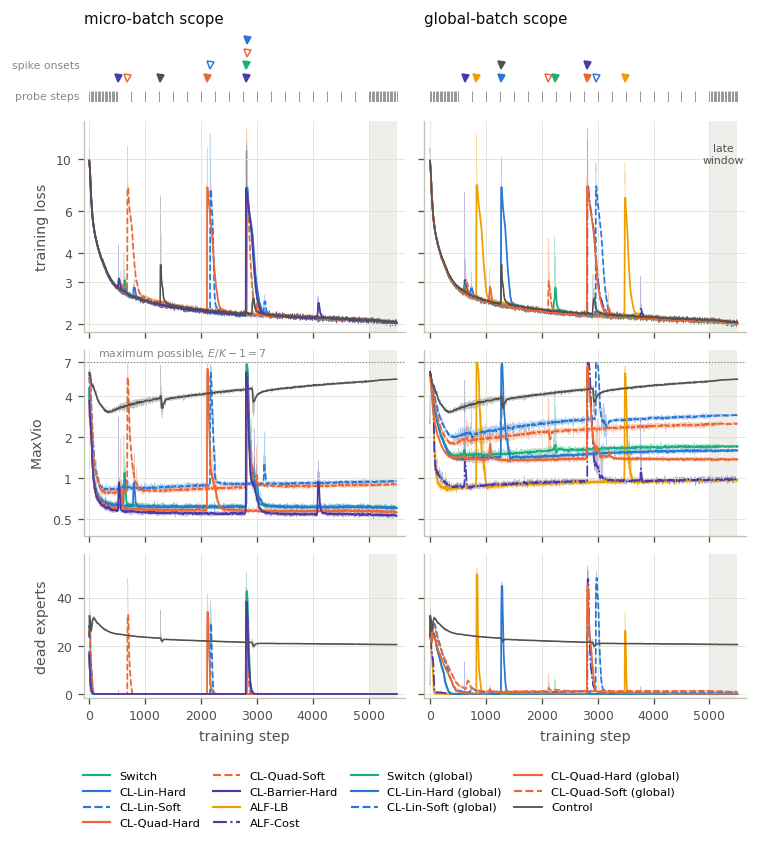

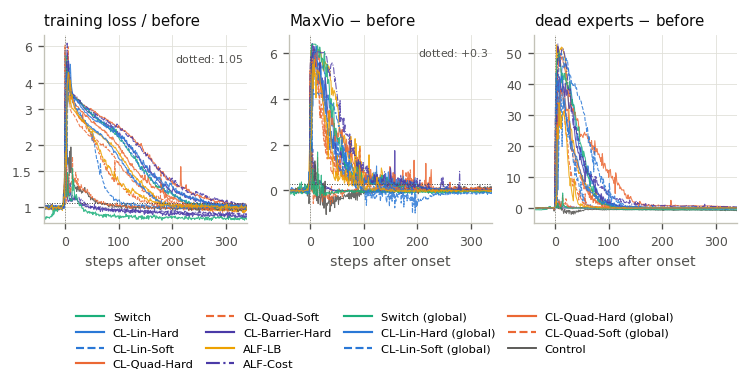

In [9]:
SCOPES = (("micro", SCOPE_TITLES["micro"]), ("global", SCOPE_TITLES["global"]))
SMOOTH = 25  # centred running median of the figure lines, in steps


def panel_arms(scope):
    """The arms of one scope facet; the control is drawn in both."""
    return [a for a in FLEET_ARMS if meta(a)["scope"] in (scope, "none")]


def arm_handles(arms=FLEET_ARMS, style=meta):
    return (
        [
            Line2D(
                [],
                [],
                color=style(a)["color"],
                ls=style(a)["dash"],
                lw=1.1 if a == "control" else 1.3,
            )
            for a in arms
        ],
        [style(a)["label"] for a in arms],
    )


def onset_levels(onsets, gap=60):
    """Stack markers whose onsets lie within `gap` steps of one another."""
    levels, placed = [], []
    for t in onsets:
        used = {lv for s, lv in placed if abs(s - t) < gap}
        lv = next(k for k in range(10) if k not in used)
        placed.append((t, lv))
        levels.append(lv)
    return levels


def fig_training_dynamics():
    rows = [
        ("loss", "training loss", True),
        ("maxvio", "$\\mathrm{MaxVio}$", True),
        ("dead", "dead experts", False),
    ]
    fig, axes = plt.subplots(
        4,
        2,
        figsize=(6.2, 7.0),
        sharex=True,
        squeeze=False,
        gridspec_kw={"height_ratios": [0.44, 1.25, 1.1, 0.85], "hspace": 0.12, "wspace": 0.06},
    )
    for j, (scope, title) in enumerate(SCOPES):
        arms = panel_arms(scope)
        # Event strip: the probe steps (ticks) and the spike onsets (one marker per spike, stacked within a cluster).
        strip = axes[0][j]
        strip.set_ylim(0, 1)
        strip.grid(False)
        for side in ("left", "bottom"):
            strip.spines[side].set_visible(False)
        strip.tick_params(left=False, labelleft=False, bottom=False)
        strip.vlines(SHARED_STEPS, 0.0, 0.16, color=MUTED, lw=0.5)
        ev = EVENTS[EVENTS.arm.isin(arms)].sort_values("onset")
        for r, lv in zip(ev.itertuples(), onset_levels(ev.onset.tolist())):
            c = meta(r.arm)["color"]
            strip.plot(
                r.onset,
                0.33 + 0.17 * lv,
                "v",
                ms=4.2,
                mec=c,
                mew=0.9,
                mfc="white" if meta(r.arm)["dash"] == "--" else c,
                clip_on=False,
            )
        strip.set_title(title, loc="left", color=INK, pad=3)
        if j == 0:
            strip.text(
                -0.012,
                0.08,
                "probe steps",
                transform=strip.get_yaxis_transform(),
                ha="right",
                va="center",
                fontsize=6.5,
                color=MUTED,
            )
            strip.text(
                -0.012,
                0.5,
                "spike onsets",
                transform=strip.get_yaxis_transform(),
                ha="right",
                va="center",
                fontsize=6.5,
                color=MUTED,
            )
        for i, (key, ylabel, log) in enumerate(rows, start=1):
            ax = axes[i][j]
            ax.axvspan(LATE_WINDOW_START, FINAL_STEP, color=GRID_INK, alpha=0.55, lw=0, zorder=0)
            for a in arms:
                ax.plot(D[a].index, D[a][key], color=meta(a)["color"], lw=0.3, alpha=0.35, zorder=1)
            for a in arms:
                ax.plot(
                    D[a].index,
                    D[a][key].rolling(SMOOTH, center=True, min_periods=1).median(),
                    meta(a)["dash"],
                    color=meta(a)["color"],
                    lw=0.95 if a == "control" else 1.05,
                    zorder=3,
                )
            if log:
                ax.set_yscale("log")
            if key == "loss":
                ax.set_ylim(1.85, 14.5)
                ax.set_yticks([2, 3, 4, 6, 10])
                ax.set_yticklabels(["2", "3", "4", "6", "10"])
                ax.minorticks_off()
                if j == 1:
                    ax.text(
                        5250,
                        10.5,
                        "late\nwindow",
                        ha="center",
                        va="center",
                        fontsize=6.5,
                        color=INK_2,
                    )
            elif key == "maxvio":
                ax.set_ylim(0.38, 8.6)
                ax.set_yticks([0.5, 1, 2, 4, 7])
                ax.set_yticklabels(["0.5", "1", "2", "4", "7"])
                ax.minorticks_off()
                ax.axhline(7.0, color=MUTED, lw=0.7, ls=":")
                if j == 0:
                    ax.text(
                        150,
                        7.25,
                        "maximum possible, $E/K - 1 = 7$",
                        fontsize=6.5,
                        color=MUTED,
                        va="bottom",
                    )
            else:
                ax.set_ylim(-1.5, 58)
            if j == 0:
                ax.set_ylabel(ylabel)
            else:
                ax.tick_params(labelleft=False)
            ax.set_xlim(-100, 5650)
        axes[-1][j].set_xlabel("training step")
    for i in range(1, 4):
        lo = min(axes[i][0].get_ylim()[0], axes[i][1].get_ylim()[0])
        hi = max(axes[i][0].get_ylim()[1], axes[i][1].get_ylim()[1])
        for j in range(2):
            axes[i][j].set_ylim(lo, hi)
    handles, labels = arm_handles()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=4,
        bbox_to_anchor=(0.5, 0.0),
        handlelength=2.4,
        columnspacing=1.1,
        fontsize=6.9,
    )
    fig.subplots_adjust(left=0.1, right=0.99, top=0.965, bottom=0.168, hspace=0.12, wspace=0.06)
    save_figure(fig, "fig_app_training_dynamics")
    plt.show()


def fig_spike_anatomy(pre=40, post=340):
    panels = [
        ("loss", "training loss / before", "ratio", 1 + LOSS_TOL),
        ("maxvio", "$\\mathrm{MaxVio}$ $-$ before", "diff", MAXVIO_TOL),
        ("dead", "dead experts $-$ before", "diff", None),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(6.3, 3.2), sharex=True, squeeze=False)
    axes = axes[0]
    for ax, (key, title, kind, thr) in zip(axes, panels):
        for r in EVENTS.itertuples():
            x = D[r.arm][key].loc[r.onset - pre : r.onset + post]
            before = getattr(
                r, {"loss": "loss_before", "maxvio": "maxvio_before", "dead": "dead_before"}[key]
            )
            y = x / before if kind == "ratio" else x - before
            ax.plot(
                x.index - r.onset,
                y,
                meta(r.arm)["dash"],
                color=meta(r.arm)["color"],
                lw=0.65 if r.arm != "control" else 0.6,
                alpha=0.85,
            )
        ax.axvline(0, color=MUTED, lw=0.6, ls=":")
        if thr is not None:
            ax.axhline(thr, color=INK_2, lw=0.6, ls=(0, (1, 1.5)))
        if kind == "ratio":
            ax.set_yscale("log")
            ax.set_yticks([1, 1.5, 2, 3, 4, 6])
            ax.set_yticklabels(["1", "1.5", "2", "3", "4", "6"])
            ax.minorticks_off()
            ax.set_ylim(0.84, 6.8)
        ax.set_title(title, loc="left", color=INK)
        ax.set_xlabel("steps after onset")
        ax.set_xlim(-pre, post)
    axes[0].text(post - 8, 5.6, "dotted: $1.05$", ha="right", va="top", fontsize=6.5, color=INK_2)
    axes[1].text(post - 8, 6.3, "dotted: $+0.3$", ha="right", va="top", fontsize=6.5, color=INK_2)
    handles, labels = arm_handles()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=4,
        bbox_to_anchor=(0.5, 0.0),
        handlelength=2.4,
        columnspacing=1.1,
        fontsize=6.9,
    )
    fig.tight_layout(rect=(0, 0.25, 1, 1), w_pad=0.8)
    save_figure(fig, "fig_app_spike_anatomy")
    plt.show()


if wanted("fig_app_training_dynamics"):
    fig_training_dynamics()
if wanted("fig_app_spike_anatomy"):
    fig_spike_anatomy()

---
## Online diagnostics (`fig_app_online_swapgap`, `fig_app_online_swapgap_zero`)

Every run logs, at every step, the swap gap and the assignment potential of its training micro batches, with the linear and the quadratic cost at price 1, and the swap gap at zero price. The 11B exports now hold them for 13 arms at full precision; the price-barrier arm comes from its per-step log (two decimals). So all 14 arms are covered. How the logged values differ from the probe diagnostics:

- every micro batch of 8,192 tokens is scored as its own game, whatever the scope of the arm;
- the swap gap is a mean over the tokens, not a sum;
- its affinities are the router logits before any bias. For a softmax router this is the game whose affinities are the log-scores; for a sigmoid router, the log-odds. So the values are compared only across arms and steps.

**Late window and drift.** A late-window value is the mean over steps 5001..5500, every step. The drift compares the mean over steps 1000..1200 with it. The earlier version of these numbers read the logs of 9 arms at every tenth step (late window 5000..5500, 51 lines). The last cell of this section recomputes them that way, so the reader can see which number changed because the arms are now 14 and which because of the sampling.

**Swap gap at zero price.** At zero price the best response of a token is its own top-K by affinity. For an arm without an expert bias the realized routing is exactly that, so its zero-price swap gap must be 0 at every step. For the two bias arms it measures how far the bias moves the selection away from the logits' own top-K.

In [10]:
ONLINE = [
    "swapgap_linear",
    "swapgap_quadratic",
    "swapgap_zero",
    "phicong_linear",
    "phicong_quadratic",
    "maxvio",
]
DRIFT_WINDOW = (1000, 1200)
late = pd.DataFrame(
    {a: FLEET[a].loc[TRAIN_LATE[0] : TRAIN_LATE[1], ONLINE].mean() for a in FLEET_ARMS}
).T
early = pd.DataFrame(
    {a: FLEET[a].loc[DRIFT_WINDOW[0] : DRIFT_WINDOW[1], ONLINE].mean() for a in FLEET_ARMS}
).T
ONLINE_LATE = late.assign(
    probe_gap_lin=PROBE_GAP.linear, probe_gap_quad=PROBE_GAP.quadratic, probe_maxvio=PROBE_MAXVIO
)
ONLINE_LATE = ONLINE_LATE.loc[PROBE_GAP.linear.sort_values().index]
with pd.option_context("display.width", 250):
    print(
        f"late window {TRAIN_LATE[0]}..{TRAIN_LATE[1]}, every step; ordered by the probe ranking (normalized gap, linear):"
    )
    print(ONLINE_LATE.round(3).to_string())

S = "online diagnostics"
note(
    S,
    "arms covered",
    f"{len(FLEET_ARMS)}: "
    + "; ".join(f"{a} {FLEET_SOURCE[a]}" for a in FLEET_ARMS if FLEET_SOURCE[a] != "W&B")
    + f"; the other {sum(FLEET_SOURCE[a] == 'W&B' for a in FLEET_ARMS)} from W&B",
)
step1 = pd.DataFrame({a: FLEET[a].loc[1, ONLINE] for a in FLEET_ARMS}).T
note(
    S,
    "step 1, range over the 14 arms",
    ", ".join(f"{k} {step1[k].min():.2f}..{step1[k].max():.2f}" for k in ONLINE),
)
balancing = [a for a in FLEET_ARMS if a != "control"]
for key, name in (("swapgap_linear", "linear"), ("swapgap_quadratic", "quadratic")):
    v = late[key]
    note(
        S,
        f"late-window swap gap per token, {name} cost",
        f"balancing arms {v[balancing].min():.3f} ({v[balancing].idxmin()}) .. "
        f"{v[balancing].max():.3f} ({v[balancing].idxmax()}); control {v['control']:.3f}",
    )
pairs = [
    ("swapgap_linear", "probe_gap_lin"),
    ("swapgap_quadratic", "probe_gap_quad"),
    ("swapgap_linear", "probe_gap_quad"),
    ("swapgap_quadratic", "probe_gap_lin"),
    ("phicong_linear", "probe_gap_lin"),
    ("phicong_quadratic", "probe_gap_quad"),
    ("maxvio", "probe_gap_lin"),
    ("maxvio", "probe_gap_quad"),
    ("swapgap_linear", "probe_maxvio"),
    ("swapgap_linear", "maxvio"),
    ("swapgap_quadratic", "maxvio"),
    ("phicong_linear", "maxvio"),
]
SPEARMAN_ONLINE = pd.DataFrame(
    [
        {
            "online": a,
            "against": b,
            "14 arms": spearman(ONLINE_LATE[a], ONLINE_LATE[b]),
            "13 without the control": spearman(
                ONLINE_LATE[a].drop("control"), ONLINE_LATE[b].drop("control")
            ),
        }
        for a, b in pairs
    ]
)
print("\nSpearman over the arms, late window (maxvio = MaxVio on the same training batches):")
print(SPEARMAN_ONLINE.round(3).to_string(index=False))
for _, r in SPEARMAN_ONLINE.iterrows():
    note(
        S,
        f"Spearman, {r.online} vs {r.against}",
        f"{r['14 arms']:.4f} (14 arms), {r['13 without the control']:.4f} (without the control)",
    )
order_sg = late.swapgap_linear.sort_values().index.tolist()
order_mv = late.maxvio.sort_values().index.tolist()
note(
    S, "linear swap gap orders the arms exactly as MaxVio on the same batches", order_sg == order_mv
)
probe_order = PROBE_GAP.linear.sort_values().index.tolist()
note(
    S,
    "arms whose rank differs, online linear swap gap vs probe gap (linear)",
    ", ".join(
        f"{a} {probe_order.index(a) + 1}->{order_sg.index(a) + 1}"
        for a in FLEET_ARMS
        if probe_order.index(a) != order_sg.index(a)
    ),
)

# Drift from steps 1000..1200 to the late window.
change = 100 * (late / early - 1)
print(f"\nchange from steps {DRIFT_WINDOW[0]}..{DRIFT_WINDOW[1]} to the late window, %:")
print(
    change[["swapgap_linear", "swapgap_quadratic", "maxvio", "phicong_linear"]].round(1).to_string()
)
for group, arms in (
    ("Switch and softplus barrier", ["switch", "rosenthal_barrier_hard"]),
    ("the four hard micro arms", LEAD_HARD),
):
    c = change.loc[arms]
    note(
        S,
        f"drift {DRIFT_WINDOW[0]}-{DRIFT_WINDOW[1]} -> late, {group}",
        "swap gap linear "
        f"{c.swapgap_linear.min():+.1f}..{c.swapgap_linear.max():+.1f} %, quadratic {c.swapgap_quadratic.min():+.1f}..{c.swapgap_quadratic.max():+.1f} %, "
        f"MaxVio {c.maxvio.min():+.1f}..{c.maxvio.max():+.1f} %, assignment potential (linear) {c.phicong_linear.min():+.1f}..{c.phicong_linear.max():+.1f} %",
    )
others = [a for a in FLEET_ARMS if a not in LEAD_HARD]
note(
    S,
    f"drift {DRIFT_WINDOW[0]}-{DRIFT_WINDOW[1]} -> late, swap gap linear, the other 10 arms",
    ", ".join(f"{a} {change.loc[a, 'swapgap_linear']:+.1f} %" for a in others),
)

# The zero-price swap gap: 0 for every arm without a bias, the cost of the bias for the two bias arms.
no_bias = [a for a in FLEET_ARMS if a not in BIAS_ARMS]
note(
    S,
    "swap gap at zero price, arms without a bias, largest value at any step",
    f"{max(FLEET[a].swapgap_zero.abs().max() for a in no_bias):.3g} ({len(no_bias)} arms x {FINAL_STEP} steps)",
)
for a in sorted(BIAS_ARMS):
    z, lin = FLEET[a].swapgap_zero, FLEET[a].swapgap_linear
    note(
        S,
        f"swap gap at zero price, {a}",
        f"step 1 {z.loc[1]:.3f}; peak {z.max():.2f} at step {int(z.idxmax())}; mean over steps "
        f"{DRIFT_WINDOW[0]}-{DRIFT_WINDOW[1]} {z.loc[DRIFT_WINDOW[0] : DRIFT_WINDOW[1]].mean():.3f}; late window {late.loc[a, 'swapgap_zero']:.3f}, "
        f"{100 * late.loc[a, 'swapgap_zero'] / late.loc[a, 'swapgap_linear']:.2f} % of its linear swap gap ({late.loc[a, 'swapgap_linear']:.3f})",
    )

# The linear assignment potential is a function of the loads alone: (1 + CV^2) / 2 + 1 / (2L) with L = 1024. Checked
# on the logs that print the load CV (two decimals, and the CV there is a mean of per-game CVs, hence a residual).
L_MICRO = 8192 * 8 // 64
resid = pd.concat(
    [
        (lines.phi_cong_linear - (1 + lines.load_cv**2) / 2 - 1 / (2 * L_MICRO)).dropna()
        for lines in (log_frame(jobs) for jobs in FLEET_LOG_JOBS.values())
    ]
)
note(
    S,
    "linear assignment potential minus (1 + CV^2)/2 + 1/(2L), logged lines of 9 arms",
    f"median {resid.median():.4f}, 5-95 % {resid.quantile(0.05):.4f}..{resid.quantile(0.95):.4f} over {len(resid)} lines",
)

late window 5001..5500, every step; ordered by the probe ranking (normalized gap, linear):
                                 swapgap_linear  swapgap_quadratic  swapgap_zero  phicong_linear  phicong_quadratic  maxvio  probe_gap_lin  probe_gap_quad  probe_maxvio
arm                                                                                                                                                                     
rosenthal_quadratic_hard                  0.269              0.836         0.000           0.521              0.377   0.572          1.056           2.202         0.645
switch                                    0.281              0.896         0.000           0.522              0.380   0.616          1.085           2.293         0.721
rosenthal_linear_hard                     0.276              0.882         0.000           0.522              0.380   0.611          1.086           2.316         0.737
rosenthal_barrier_hard                    0.268              0.8

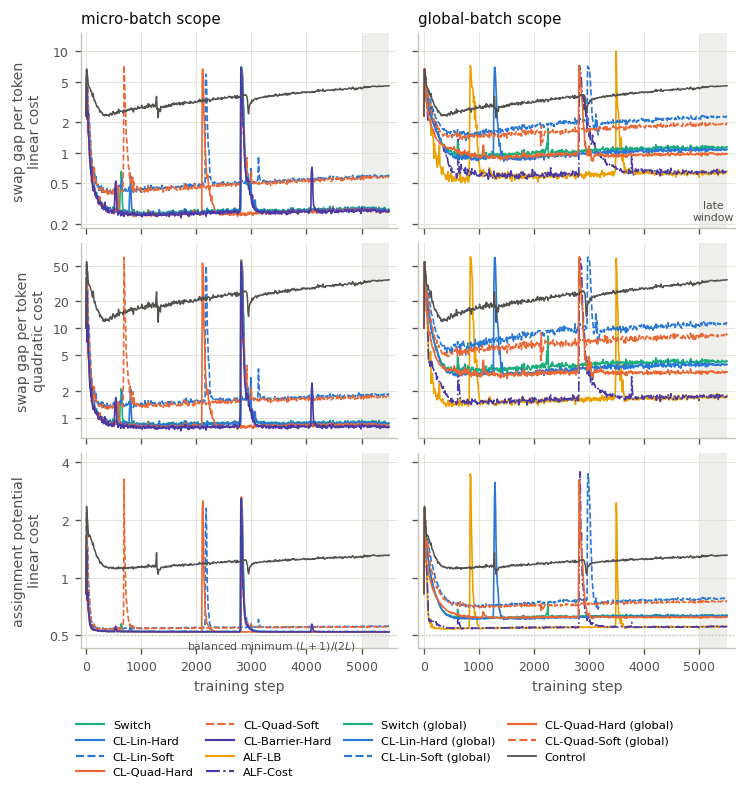

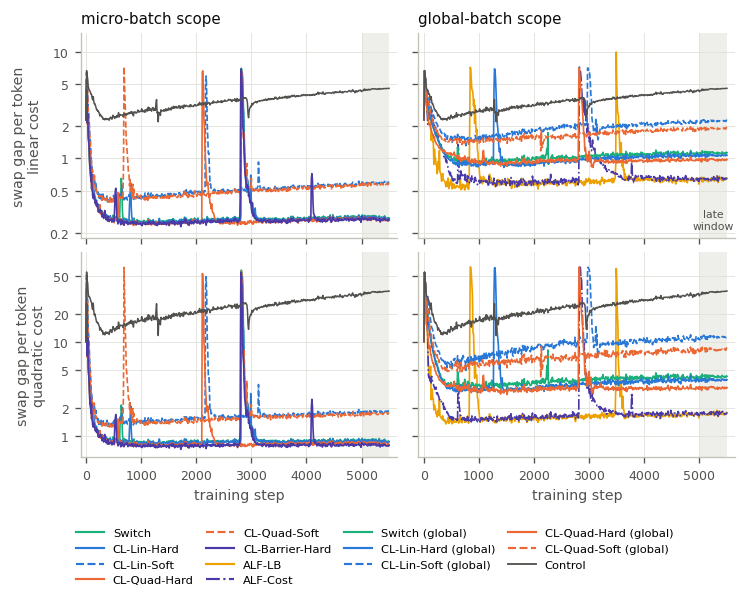

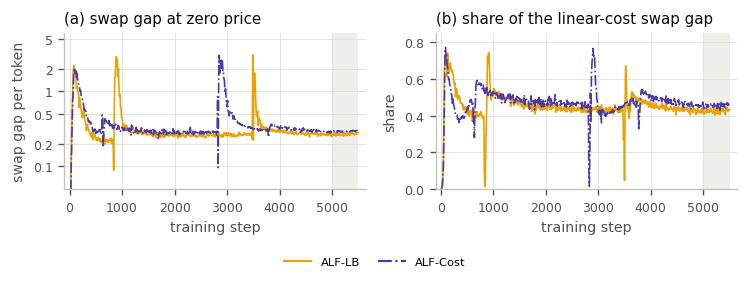

In [11]:
def every_tenth(series):
    """The steps the figure draws: step 1 and every tenth step, as the logs of most arms print them."""
    return series[(series.index % 10 == 0) | (series.index == 1)]


# (metric, y label, dotted reference line, y limits, y ticks)
ONLINE_ROWS = (
    (
        "swapgap_linear",
        "swap gap per token\nlinear cost",
        None,
        (0.18, 15),
        [0.2, 0.5, 1, 2, 5, 10],
    ),
    (
        "swapgap_quadratic",
        "swap gap per token\nquadratic cost",
        None,
        (0.6, 90),
        [1, 2, 5, 10, 20, 50],
    ),
    (
        "phicong_linear",
        "assignment potential\nlinear cost",
        (L_MICRO + 1) / (2 * L_MICRO),
        (0.43, 4.5),
        [0.5, 1, 2, 4],
    ),
)


def fig_online_swapgap(
    rows=ONLINE_ROWS, height=6.6, legend_space=0.1, name="fig_app_online_swapgap"
):
    """One row of panels per entry of `rows`; the legend takes the bottom `legend_space` of the figure."""
    fig, axes = plt.subplots(len(rows), 2, figsize=(6.3, height), sharex=True, sharey="row")
    for i, (key, ylabel, floor, ylim, yticks) in enumerate(rows):
        for j, (scope, title) in enumerate(SCOPES):
            ax = axes[i][j]
            ax.axvspan(LATE_WINDOW_START, FINAL_STEP, color=GRID_INK, alpha=0.55, lw=0, zorder=0)
            for a in panel_arms(scope):
                s = every_tenth(FLEET[a][key])
                ax.plot(
                    s.index,
                    s.values,
                    meta(a)["dash"],
                    color=meta(a)["color"],
                    lw=0.9 if a == "control" else 1.0,
                    zorder=2,
                )
            ax.set_yscale("log")
            ax.set_ylim(*ylim)
            ax.yaxis.set_major_locator(FixedLocator(yticks))
            ax.yaxis.set_minor_locator(NullLocator())
            ax.yaxis.set_minor_formatter(NullFormatter())
            ax.set_yticklabels([f"{t:g}" for t in yticks])
            if floor is not None:
                ax.axhline(floor, color=MUTED, lw=0.8, ls=":", zorder=1)
                if j == 0:
                    ax.text(
                        4900,
                        floor * 0.955,
                        "balanced minimum $(L+1)/(2L)$",
                        fontsize=6.5,
                        color=INK_2,
                        ha="right",
                        va="top",
                    )
            if i == 0:
                ax.set_title(title, loc="left", color=INK)
                if j == 1:
                    ax.text(
                        5250,
                        0.21,
                        "late\nwindow",
                        fontsize=6.5,
                        color=INK_2,
                        ha="center",
                        va="bottom",
                    )
            if i == len(rows) - 1:
                ax.set_xlabel("training step")
            if j == 0:
                ax.set_ylabel(ylabel)
            ax.set_xlim(-100, 5650)
    handles, labels = arm_handles()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=4,
        bbox_to_anchor=(0.5, 0.0),
        handlelength=2.4,
        columnspacing=1.1,
        fontsize=6.9,
    )
    fig.tight_layout(rect=(0, legend_space, 1, 1), h_pad=0.6)
    save_figure(fig, name)
    plt.show()


def fig_online_swapgap_zero():
    bias = [a for a in FLEET_ARMS if a in BIAS_ARMS]
    fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.35))
    for a in bias:
        m = meta(a)
        zero = every_tenth(FLEET[a].swapgap_zero).loc[10:]
        share = every_tenth(FLEET[a].swapgap_zero / FLEET[a].swapgap_linear).loc[10:]
        axes[0].plot(zero.index, zero.values, m["dash"], color=m["color"], lw=1.0, label=m["label"])
        axes[1].plot(
            share.index, share.values, m["dash"], color=m["color"], lw=1.0, label=m["label"]
        )
    axes[0].set_yscale("log")
    axes[0].set_ylim(0.05, 6)
    axes[0].yaxis.set_major_locator(FixedLocator([0.1, 0.2, 0.5, 1, 2, 5]))
    axes[0].yaxis.set_minor_locator(NullLocator())
    axes[0].set_yticklabels(["0.1", "0.2", "0.5", "1", "2", "5"])
    axes[0].set_ylabel("swap gap per token")
    axes[0].set_title("(a) swap gap at zero price", loc="left", color=INK)
    axes[1].set_ylim(0, 0.85)
    axes[1].set_ylabel("share")
    axes[1].set_title("(b) share of the linear-cost swap gap", loc="left", color=INK)
    for ax in axes:
        ax.axvspan(LATE_WINDOW_START, FINAL_STEP, color=GRID_INK, alpha=0.55, lw=0, zorder=0)
        ax.set_xlim(-100, 5650)
        ax.set_xlabel("training step")
    handles, labels = arm_handles(bias)
    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=2,
        bbox_to_anchor=(0.5, 0.0),
        handlelength=2.4,
        columnspacing=1.6,
        fontsize=6.9,
    )
    fig.tight_layout(rect=(0, 0.1, 1, 1), w_pad=1.2)
    save_figure(fig, "fig_app_online_swapgap_zero")
    plt.show()


if wanted("fig_app_online_swapgap"):
    fig_online_swapgap()
# The main text shows the two swap-gap rows only, without the assignment potential.
if wanted("fig_ex_swapgap"):
    fig_online_swapgap(ONLINE_ROWS[:2], height=5.0, legend_space=0.13, name="fig_ex_swapgap")
if wanted("fig_app_online_swapgap_zero"):
    fig_online_swapgap_zero()

In [12]:
# The earlier definition, for comparison: the 9 arms with logs, every tenth logged step, late window 5000..5500 (51
# lines), drift window 1000..1200 (21 lines), two decimals. Here only to show which numbers changed and why.
LOG_FIELD = {key: field for key, (_, field) in EXPORT_METRICS.items()}
old = {}
for arm, jobs in FLEET_LOG_JOBS.items():
    lines = log_frame(jobs)
    lines = lines[lines.index % 10 == 0]
    old[arm] = {
        "late": lines.loc[5000:5500, [LOG_FIELD[k] for k in ONLINE]].mean().set_axis(ONLINE),
        "early": lines.loc[1000:1200, [LOG_FIELD[k] for k in ONLINE]].mean().set_axis(ONLINE),
    }
old_late = pd.DataFrame({a: v["late"] for a, v in old.items()}).T
old_early = pd.DataFrame({a: v["early"] for a, v in old.items()}).T
old_change = 100 * (old_late / old_early - 1)
S = "online diagnostics, earlier definition (9 arms, logs, every 10th step)"
for key, gap in (("swapgap_linear", "linear"), ("swapgap_quadratic", "quadratic")):
    note(
        S,
        f"Spearman, {key} vs probe gap ({gap})",
        f"{spearman(old_late[key], PROBE_GAP[gap]):.4f}; with the new definition on the same 9 arms "
        f"{spearman(late.loc[old_late.index, key], PROBE_GAP[gap]):.4f}",
    )
    v = old_late[key]
    note(
        S,
        f"late-window swap gap, {gap} cost",
        f"{v.min():.3f}..{v.max():.3f}; new definition, same 9 arms "
        f"{late.loc[old_late.index, key].min():.3f}..{late.loc[old_late.index, key].max():.3f}",
    )
note(
    S,
    "linear swap gap orders the 9 arms as MaxVio",
    old_late.swapgap_linear.sort_values().index.tolist()
    == old_late.maxvio.sort_values().index.tolist(),
)
note(
    S,
    "Spearman, swapgap_quadratic vs MaxVio (same lines)",
    f"{spearman(old_late.swapgap_quadratic, old_late.maxvio):.4f}",
)
c = old_change.loc[["switch", "rosenthal_barrier_hard"]]
note(
    S,
    "drift, Switch and softplus barrier",
    f"swap gap linear {c.swapgap_linear.min():+.1f}..{c.swapgap_linear.max():+.1f} %, "
    f"quadratic {c.swapgap_quadratic.min():+.1f}..{c.swapgap_quadratic.max():+.1f} %, MaxVio {c.maxvio.min():+.1f}..{c.maxvio.max():+.1f} %",
)
new_change = change.loc[
    ["switch", "rosenthal_barrier_hard"], ["swapgap_linear", "swapgap_quadratic", "maxvio"]
]
shift = (new_change - old_change.loc[new_change.index, new_change.columns]).abs().max().max()
note(
    S,
    "drift of Switch and softplus barrier: largest change between the two definitions",
    f"{shift:.2f} percentage points",
)
shift9 = (
    (
        late.loc[old_late.index, ["swapgap_linear", "swapgap_quadratic", "maxvio"]]
        / old_late[["swapgap_linear", "swapgap_quadratic", "maxvio"]]
        - 1
    )
    .abs()
    .max()
    .max()
)
note(
    S,
    "late-window values of the 9 arms: largest relative change between the two definitions",
    f"{100 * shift9:.2f} %",
)

**Reading the online diagnostics.** On the nine arms that the earlier version had from their logs, the new source and the every-step late window leave the Spearman correlations unchanged and move the late-window values by less than one percent, enough to change one quoted bound in its last digit; the drift percentages move by a fraction of a percentage point (the two "largest change" rows of the earlier-definition block). The correlations with the probe ranking change because five arms are added: the micro-batch linear hard, quadratic hard and quadratic soft arms, ALF-LB and the control. On training batches, the two soft micro-batch arms come before the two bias arms under the linear swap gap, as they do under MaxVio on the same batches, while the probes order them the other way. The linear swap gap still orders all 14 arms exactly as MaxVio on the same batches. The drift of the swap gap at constant loads, which the earlier version showed for Switch and the softplus barrier, holds for all four hard micro-batch arms.

**Swap gap at zero price.** It is exactly 0 at every step for the twelve arms without a bias, as it must be. For the two bias arms it stays at a similar level for most of training and makes up a large share of their swap gap under the linear cost (numbers in the last cell). So in the logit game, a large part of the swap gap of a bias arm is the bias itself, which moves tokens off their highest logits even at zero congestion price. `fig_app_online_swapgap_zero` shows this; the thesis does not read it yet.

---
## Collapse induction (`fig_app_collapse_induction`)

Two short runs collapse the router on purpose, from the same initialization (global batch 128, seed 9830):

- **negative auxiliary loss:** the micro-batch Switch loss with weight −0.01 and the positive z-loss, 150 steps on 4 GPUs. Source: its W&B export, every step.
- **negative z-loss:** the z-loss with weight −0.001 and no balancing, sigmoid scores, 500 steps on 16 GPUs. Source: its training log, every tenth step, with the loss averaged over the steps since the previous line (rule 2). Its W&B history was rejected, and the export named after it holds the softmax run (rule 3).

`INDUCTIONS` in the sources cell names each source; the check section has tested both against the logs. The dotted lines of the figure mark the checkpoints the races start from: steps 125 and 150 of the negative auxiliary loss and step 500 of the negative z-loss.

negative auxiliary loss: W&B export collapse-induce/wandb_induce_negaux (run induce_negaux-induce-negaux), every step, equal to the log of job 3391576; 4 GPUs, global batch 128, seed 9830, score function sigmoid, z-loss weight 0.001, aux-loss weight -0.01, 150 steps
negative z-loss: training log of job 3315605 (moe_train_3315605.log), every 10th step; 16 GPUs, global batch 128, seed 9830, score function sigmoid, z-loss weight -0.001, aux-loss weight 0.0, 500 steps


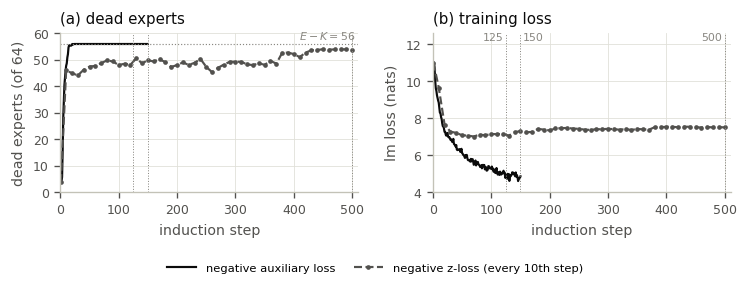

In [13]:
def induction_series(entry):
    """(per-step frame of one induction, source text) from its INDUCTIONS entry."""
    if entry["source"] == "wandb":
        runs = EXPORTS[entry["export"]]
        assert len(runs) == 1, f"{entry['export']}: {len(runs)} runs, name the run"
        run, frame = next(iter(runs.items()))
        row = CHECK[(CHECK.export == entry["export"]) & (CHECK.run == run)].iloc[0]
        assert row.verdict == "pass" and row["checked against"] == entry["job"], (
            f"{entry['export']}: the check against job {entry['job']} did not pass ({row.verdict})"
        )
        return (
            frame,
            f"W&B export {entry['export']} (run {run}), every step, equal to the log of job {entry['job']}",
        )
    lines = log_frame([entry["job"]])
    frame = lines.rename(columns={field: key for key, (_, field) in EXPORT_METRICS.items()})
    return (
        frame,
        f"training log of job {entry['job']} ({LOG_INFO.file[entry['job']]}), every {LOG_INFO.log_interval[entry['job']]}th step",
    )


INDUCTION = {}
for name, entry in INDUCTIONS.items():
    INDUCTION[name], source = induction_series(entry)
    job = entry["job"]
    print(
        f"{name}: {source}; {LOG_INFO.world_size[job]} GPUs, global batch {LOG_INFO.global_batch_size[job]}, seed "
        f"{LOG_INFO.seed[job]}, score function {LOG_INFO.moe_router_score_function[job]}, z-loss weight "
        f"{LOG_INFO.moe_z_loss_coeff[job]}, aux-loss weight {LOG_INFO.moe_aux_loss_coeff[job]}, {LOG_INFO.train_iters[job]} steps"
    )
    note("collapse induction", f"{name}, source", source)
for prefix, held in EXPORT_HOLDS.items():
    note(
        "collapse induction",
        f"export {prefix}",
        f"holds {held['holds']} (job {held['job']}); not used",
    )


def held_from(series, condition):
    """First step from which `condition` holds at every later step of the series."""
    ok = condition(series)
    held = ok[::-1].cummin()[::-1]
    return int(held.index[held.to_numpy()][0]) if held.any() else None


neg, negz = INDUCTION["negative auxiliary loss"], INDUCTION["negative z-loss"]
S = "collapse induction"
note(
    S,
    "negative auxiliary loss: dead experts at steps 10, 20, 37, 125, 150",
    ", ".join(f"{neg.dead_experts.loc[s]:.2f}" for s in (10, 20, 37, 125, 150)),
)
note(
    S,
    "negative auxiliary loss: all but K = 8 experts dead (56) from step",
    held_from(neg.dead_experts, lambda v: v >= 56 - 1e-9),
)
note(
    S,
    "negative auxiliary loss: MaxVio >= 6.99 from step",
    held_from(neg.maxvio, lambda v: v >= 6.99),
)
note(
    S,
    "negative auxiliary loss: loss at steps 1, 125, 150",
    ", ".join(f"{neg.lm_loss.loc[s]:.3f}" for s in (1, 125, 150)),
)
note(
    S,
    "negative z-loss (log lines): dead experts at steps 10, 100, 300, 500",
    ", ".join(f"{negz.dead_experts.loc[s]:.2f}" for s in (10, 100, 300, 500)),
)
note(
    S,
    "negative z-loss (log lines): MaxVio >= 6.99 from logged step",
    held_from(negz.maxvio, lambda v: v >= 6.99),
)
note(
    S,
    "negative z-loss (log lines): lowest loss, loss at step 500",
    f"{negz.lm_loss.min():.3f} (line of step {int(negz.lm_loss.idxmin())}), {negz.lm_loss.loc[500]:.3f}",
)
note(
    S,
    "negative z-loss (log lines): z-loss before its weight at step 500, grad norm at step 500",
    f"{LOG_LINES[INDUCTIONS['negative z-loss']['job']].z_loss.loc[500]:.0f}, {negz.grad_norm.loc[500]:.1f}",
)


def fig_collapse_induction():
    fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.35))
    for ax, key, title, ylabel in zip(
        axes,
        ("dead_experts", "lm_loss"),
        ("(a) dead experts", "(b) training loss"),
        ("dead experts (of 64)", "lm loss (nats)"),
    ):
        ax.plot(neg.index, neg[key], "-", color=INK, lw=1.3, label="negative auxiliary loss")
        ax.plot(
            negz.index,
            negz[key],
            "--",
            color=GRAY,
            lw=1.3,
            marker="o",
            ms=1.8,
            label="negative z-loss (every 10th step)",
        )
        for step in (125, 150, 500):
            ax.axvline(step, color=MUTED, lw=0.6, ls=":")
        ax.set_xlim(0, 510)
        ax.set_xticks([0, 100, 200, 300, 400, 500])
        ax.set_xlabel("induction step")
        ax.set_ylabel(ylabel)
        ax.set_title(title, loc="left", color=INK)
    axes[0].axhline(56, color=MUTED, lw=0.7, ls=":")
    axes[0].set_ylim(0, 60)
    axes[0].text(505, 57, r"$E - K = 56$", fontsize=6.6, color=MUTED, ha="right", va="bottom")
    axes[1].set_ylim(4, 12.6)
    for step, ha, dx in ((125, "right", -4), (150, "left", 4), (500, "right", -4)):
        axes[1].text(step + dx, 12.1, str(step), fontsize=6.6, color=MUTED, ha=ha, va="bottom")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=2,
        bbox_to_anchor=(0.5, -0.02),
        handlelength=2.6,
        columnspacing=1.6,
        fontsize=6.9,
    )
    fig.tight_layout(rect=(0, 0.09, 1, 1), w_pad=1.4)
    save_figure(fig, "fig_app_collapse_induction")
    plt.show()


if wanted("fig_app_collapse_induction"):
    fig_collapse_induction()

---
## The race from step 125 (`fig_step125_race`, `fig_step125_variants`)

Every arm restarts from step 125 of the negative-auxiliary-loss induction, the last checkpoint before its anneal, with a fresh optimizer and learning-rate schedule (warmup 40 steps, anneal over steps 1800..2000), the same seed and batches, and trains 2000 steps. Seven canonical arms (all loss arms at the global-batch scope) and three variants, each changing one setting of a canonical arm. Source: the W&B export, one value per step, checked against the logs at all 2000 steps above.

**Definitions**, every one computed on the raw per-step series:

- **Dead < 1, first:** the first step with fewer than one dead expert. **Revived:** the first step from which the dead experts stay below 1 at every step up to step 1800, where the anneal starts.
- **Plateau:** the mean MaxVio over steps 1001..1800. **Settled:** the first step at which the trailing 25-step mean of MaxVio is within +0.1 of the arm's plateau.
- **MaxVio < 2 or < 1, first / held:** the first step with a raw value below the threshold / the first step from which the trailing 25-step mean stays below it up to step 1800.
- **Loss:** all arms see the same batches, so the loss minus the control's loss at the same step is a paired difference. **Crossover:** the first step at or after 50 from which the arm's loss is below the control's for 200 consecutive steps, within steps 1..1800. **Revival peak:** the largest trailing 25-step mean of the paired difference over steps 1..300, which hold every arm's revival.
- **Δ val. loss:** the final validation loss of the arm's log (the "on validation set" line at step 2000) minus the control's.

In [14]:
PLATEAU = (1001, 1800)  # after recovery, before the anneal
HOLD_TO = 1800  # revival must hold up to the start of the anneal
TRAIL = 25  # trailing window of the settle and held criteria and of the loss peaks
SETTLE_TOL = 0.1
REVIVAL_PEAK_WINDOW = (1, 300)

step125_runs = EXPORTS[STEP125_EXPORT]
assert set(step125_runs) == set(STEP125_RUNS), set(step125_runs) ^ set(STEP125_RUNS)
assert (CHECK[CHECK.export == STEP125_EXPORT].verdict == "pass").all(), (
    "a step-125 run failed the check"
)
R125 = {STEP125_RUNS[run]: frame for run, frame in step125_runs.items()}
R125_JOB = {
    STEP125_RUNS[run]: CHECK[(CHECK.export == STEP125_EXPORT) & (CHECK.run == run)][
        "checked against"
    ].iloc[0]
    for run in step125_runs
}


def trailing(series, window=TRAIL):
    return series.rolling(window, min_periods=window).mean()


def first_step(mask):
    hit = mask[mask]
    return int(hit.index[0]) if len(hit) else None


def first_held(values, condition, hold_to=HOLD_TO):
    """First step t such that `condition` holds at every step in [t, hold_to]."""
    ok = condition(values.loc[:hold_to])
    held = ok[::-1].cummin()[::-1]
    return first_step(held.astype(bool))


def final_validation(job):
    final = [v for v in LOG_VALIDATION[job] if v["final"]]
    assert len(final) == 1, f"job {job}: {len(final)} final validation lines"
    return final[0]["step"], final[0]["lm loss"]


def race_statistics(runs, control="control"):
    ctrl = runs[control]
    rows = {}
    for arm, d in runs.items():
        mv, de, lm = d.maxvio, d.dead_experts, d.lm_loss
        plateau = mv.loc[PLATEAU[0] : PLATEAU[1]]
        r = {
            "dead<1 first": first_step(de < 1),
            "revived": first_held(de, lambda v: v < 1),
            "dead=0 first": first_step(de == 0),
        }
        for thr in (2, 1):
            r[f"MaxVio<{thr} first"] = first_step(mv < thr)
            r[f"MaxVio<{thr} held"] = first_held(
                trailing(mv).fillna(np.inf), lambda v, t=thr: v < t
            )
        r["plateau"] = plateau.mean()
        r["plateau sd"] = plateau.std()
        r["settled"] = (
            first_step(trailing(mv) <= plateau.mean() + SETTLE_TOL) if arm != control else None
        )
        r["dead 1001-1800"] = de.loc[PLATEAU[0] : PLATEAU[1]].mean()
        r["dead @2000"] = de.loc[2000]
        r["MaxVio 1901-2000"] = mv.loc[1901:2000].mean()
        r["lowest MaxVio"] = mv.min()
        r["lowest MaxVio step"] = int(mv.idxmin())
        diff = lm - ctrl.lm_loss
        r["loss - control 1001-1800"] = diff.loc[PLATEAU[0] : PLATEAU[1]].mean()
        peak = trailing(diff).loc[REVIVAL_PEAK_WINDOW[0] : REVIVAL_PEAK_WINDOW[1]]
        r["revival peak"] = peak.max() if arm != control else None
        r["revival peak step"] = int(peak.idxmax()) if arm != control else None
        below = (lm < ctrl.lm_loss).loc[:HOLD_TO]
        r["crossover"] = None
        if arm != control:
            for s in below.index:
                window = below.loc[s : s + 199]
                if s >= 50 and len(window) == 200 and window.all():
                    r["crossover"] = int(s)
                    break
        rows[arm] = r
    table = pd.DataFrame(rows).T
    steps = [
        "dead<1 first",
        "revived",
        "dead=0 first",
        "MaxVio<2 first",
        "MaxVio<2 held",
        "MaxVio<1 first",
        "MaxVio<1 held",
        "settled",
        "lowest MaxVio step",
        "revival peak step",
        "crossover",
    ]
    floats = [c for c in table.columns if c not in steps]
    return table.astype({**dict.fromkeys(steps, "Int64"), **dict.fromkeys(floats, float)})


T125 = race_statistics(R125)
val = {arm: final_validation(job) for arm, job in R125_JOB.items()}
assert {step for step, _ in val.values()} == {2000}
T125["val loss"] = pd.Series({arm: v for arm, (_, v) in val.items()})
T125["Δ val"] = T125["val loss"] - T125.loc["control", "val loss"]
T125 = T125.loc[STEP125_CANONICAL + STEP125_VARIANTS]
with pd.option_context("display.width", 250, "display.max_columns", 40):
    print(T125.T.to_string(float_format=lambda v: f"{v:.4f}"))

S = "race from step 125"
first = pd.DataFrame({a: d.loc[1] for a, d in R125.items()}).T
note(
    S,
    "step 1, every run",
    f"MaxVio {first.maxvio.min():.2f}..{first.maxvio.max():.2f}, dead {first.dead_experts.min():.2f}..{first.dead_experts.max():.2f}, "
    f"loss {first.lm_loss.min():.4f}..{first.lm_loss.max():.4f}",
)
job = R125_JOB["control"]
note(
    S,
    "configuration (logs)",
    f"{LOG_INFO.world_size[job]} GPUs, global batch {LOG_INFO.global_batch_size[job]} x "
    f"{LOG_INFO.seq_length[job]} tokens, seed {LOG_INFO.seed[job]}, {LOG_INFO.train_iters[job]} steps = "
    f"{int(LOG_INFO.train_iters[job]) * int(LOG_INFO.global_batch_size[job]) * int(LOG_INFO.seq_length[job]):,} tokens",
)
cols = ["dead<1 first", "revived", "settled", "plateau", "dead 1001-1800", "Δ val"]
fmt = {
    "dead<1 first": "{:.0f}",
    "revived": "{:.0f}",
    "settled": "{:.0f}",
    "plateau": "{:.3f}",
    "dead 1001-1800": "{:.3f}",
    "Δ val": "{:+.4f}",
}
for arm in STEP125_CANONICAL + STEP125_VARIANTS:
    r = T125.loc[arm]
    note(
        S,
        f"table row, {arm}",
        ", ".join(f"{c} " + ("---" if pd.isna(r[c]) else fmt[c].format(r[c])) for c in cols),
    )
note(S, "control validation loss", f"{T125.loc['control', 'val loss']:.4f}")
loss_arms = [
    "switch_global",
    "rosenthal_linear_hard_global",
    "rosenthal_quadratic_hard_global",
    "rosenthal_barrier_hard_global",
]
bias = ["alflb", "rosenthal_price_barrier"]
balancing = loss_arms + bias
t = T125.loc[loss_arms]
note(
    S,
    "loss arms: dead<1 first, revived",
    f"{t['dead<1 first'].min()}..{t['dead<1 first'].max()}, {t.revived.min()}..{t.revived.max()}",
)
note(
    S,
    "loss arms: settled, plateaus",
    f"{t.settled.min()}..{t.settled.max()}; "
    + ", ".join(f"{a} {T125.loc[a, 'plateau']:.3f}" for a in loss_arms),
)
note(
    S,
    "bias arms: dead<1 first, revived, settled, plateau",
    "; ".join(
        f"{a} {T125.loc[a, 'dead<1 first']}, {T125.loc[a, 'revived']}, {T125.loc[a, 'settled']}, {T125.loc[a, 'plateau']:.3f}"
        for a in bias
    ),
)
pbd = R125["rosenthal_price_barrier"].dead_experts
note(
    S,
    "price barrier: the step that sets its revival",
    f"{pbd.loc[:HOLD_TO][pbd.loc[:HOLD_TO] >= 1].index.max()} with "
    f"{pbd.loc[pbd.loc[:HOLD_TO][pbd.loc[:HOLD_TO] >= 1].index.max()]:.2f} dead; trailing 25-step mean over steps 200..700 "
    f"{trailing(pbd).loc[200:700].min():.2f}..{trailing(pbd).loc[200:700].max():.2f}; below 0.1 from step "
    f"{first_held(trailing(pbd).fillna(np.inf), lambda v: v < 0.1)}",
)
note(
    S,
    "loss arms: any step with MaxVio below 1",
    bool((T125.loc[loss_arms, "MaxVio<1 first"].notna()).any()),
)
note(
    S,
    "loss arms: lowest MaxVio (step)",
    ", ".join(
        f"{a} {T125.loc[a, 'lowest MaxVio']:.2f} ({T125.loc[a, 'lowest MaxVio step']})"
        for a in loss_arms
    ),
)
sd = T125.loc[balancing, "plateau sd"]
note(
    S,
    "plateau sd, balancing arms; tolerance 0.1 / sd",
    f"{sd.min():.3f}..{sd.max():.3f}; {SETTLE_TOL / sd.max():.2f}..{SETTLE_TOL / sd.min():.2f}",
)
note(
    S,
    "twins (Switch, linear hard): plateau difference, revival",
    f"{abs(T125.loc['switch_global', 'plateau'] - T125.loc['rosenthal_linear_hard_global', 'plateau']):.4f}; "
    f"{T125.loc['switch_global', 'revived']} / {T125.loc['rosenthal_linear_hard_global', 'revived']}",
)
steep = [
    T125.loc[a, "plateau"] - T125.loc[b, "plateau"]
    for a in ("switch_global", "rosenthal_linear_hard_global")
    for b in ("rosenthal_quadratic_hard_global", "rosenthal_barrier_hard_global")
]
note(S, "steeper costs settle lower by", f"{min(steep):.3f}..{max(steep):.3f}")
note(
    S,
    "crossover, loss arms / bias arms",
    f"{t.crossover.min()}..{t.crossover.max()} / "
    f"{T125.loc[bias, 'crossover'].min()}..{T125.loc[bias, 'crossover'].max()}",
)
note(
    S,
    "revival peak of loss - control (trailing 25, steps 1..300)",
    "; ".join(
        f"{a} {T125.loc[a, 'revival peak']:+.4f} at {T125.loc[a, 'revival peak step']}"
        for a in balancing
    ),
)
note(
    S,
    "loss - control over steps 1001..1800, balancing arms",
    f"{T125.loc[balancing, 'loss - control 1001-1800'].min():+.4f}.."
    f"{T125.loc[balancing, 'loss - control 1001-1800'].max():+.4f}",
)
note(
    S,
    "Δ val, balancing arms",
    f"{T125.loc[balancing, 'Δ val'].min():+.4f}..{T125.loc[balancing, 'Δ val'].max():+.4f}",
)
note(
    S,
    "twins: Δ val difference",
    f"{abs(T125.loc['switch_global', 'Δ val'] - T125.loc['rosenthal_linear_hard_global', 'Δ val']):.4f}",
)
S = "race from step 125, variants"
for v in STEP125_VARIANTS:
    base = RACE_BASE[v]
    note(
        S,
        f"{v} vs {base}",
        f"revived {T125.loc[v, 'revived']} vs {T125.loc[base, 'revived']}; plateau {T125.loc[v, 'plateau']:.3f} "
        f"(sd {T125.loc[v, 'plateau sd']:.3f}) vs {T125.loc[base, 'plateau']:.3f}; dead 1001-1800 {T125.loc[v, 'dead 1001-1800']:.3f}, "
        f"at 2000 {T125.loc[v, 'dead @2000']:.3f}; revival peak {T125.loc[v, 'revival peak']:+.3f} at {T125.loc[v, 'revival peak step']}; "
        f"Δ val {T125.loc[v, 'Δ val']:+.4f} vs {T125.loc[base, 'Δ val']:+.4f}; crossover "
        f"{'none within steps 1..1800' if pd.isna(T125.loc[v, 'crossover']) else T125.loc[v, 'crossover']}",
    )
note(
    S,
    "fastest revival of all ten runs",
    f"{T125.revived.astype(float).idxmin()} at {int(T125.revived.astype(float).min())}",
)
# How the revival unfolds: when the loss rises above the control's, and the stall of the dead experts in the bias
# arms. Centred 5-step means for the loss excess and the fall of MaxVio, trailing 5-step means for the dead experts.
S = "race from step 125, revival dynamics"
ctrl_loss = R125["control"].lm_loss
for arm in [a for a in STEP125_CANONICAL if a != "control"]:
    d = R125[arm]
    excess = (d.lm_loss - ctrl_loss).rolling(5, center=True).mean().loc[1:400]
    fall = (-d.maxvio.diff()).rolling(5, center=True).mean().loc[1:400]
    note(
        S,
        f"{arm}: loss-excess peak, steepest MaxVio fall, dead<1 first",
        f"{excess.idxmax()} ({excess.max():+.4f}), {fall.idxmax()}, {T125.loc[arm, 'dead<1 first']}",
    )
for arm in sorted(BIAS_ARMS):
    d = R125[arm]
    dead5 = d.dead_experts.rolling(5).mean()
    low_step = dead5.loc[20:50].idxmin()
    high_step = dead5.loc[low_step:80].idxmax()
    excess = (d.lm_loss - ctrl_loss).rolling(5, center=True).mean()
    note(
        S,
        f"{arm}: dead experts fall to, rise again to (trailing 5-step mean)",
        f"{dead5[low_step]:.1f} at {low_step}, {dead5[high_step]:.1f} at {high_step}; MaxVio {d.maxvio.rolling(5).mean()[low_step]:.2f} -> "
        f"{d.maxvio.rolling(5).mean()[high_step]:.2f}; largest loss excess in between {excess.loc[low_step:high_step].max():+.4f}",
    )
    note(
        S,
        f"{arm}: correlation of loss - control with dead experts, same step, steps 1..300",
        f"{(d.lm_loss - ctrl_loss).loc[1:300].corr(d.dead_experts.loc[1:300]):+.2f}",
    )
bal = [a for a in STEP125_CANONICAL if a != "control"]
late = pd.DataFrame({a: R125[a].lm_loss - ctrl_loss for a in bal}).loc[801:2000]
note(
    S,
    "after step 800: largest common dip of loss - control (a spike of the control)",
    f"step {late.mean(axis=1).idxmin()}, {late.mean(axis=1).min():+.3f} nats averaged over the balancing arms",
)
note(
    S,
    "after step 800: largest loss - control per arm",
    "; ".join(f"{a} {late[a].max():+.3f} at {late[a].idxmax()}" for a in bal),
)

                         switch_global rosenthal_linear_hard_global rosenthal_quadratic_hard_global rosenthal_barrier_hard_global   alflb rosenthal_price_barrier control rosenthal_barrier_hard_global_coeff3e-2 alflb_eta1e-2 rosenthal_price_barrier_eta1e-2
dead<1 first                        42                           42                              37                            41     106                     106    <NA>                                      36           194                             366
revived                             44                           44                              37                            41     123                     392    <NA>                                      36           285                             570
dead=0 first                       113                          136                             109                           105     149                     143    <NA>                                      57           412         

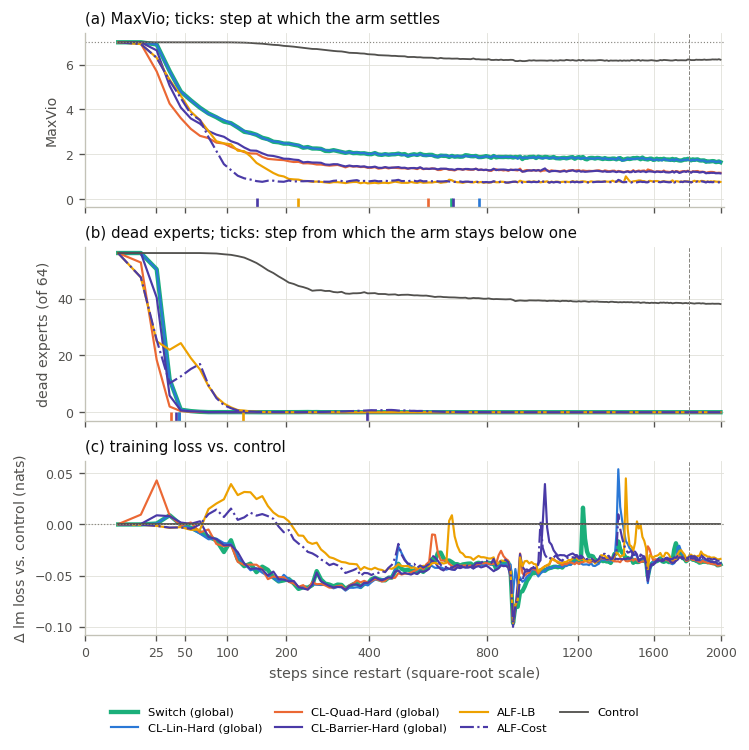

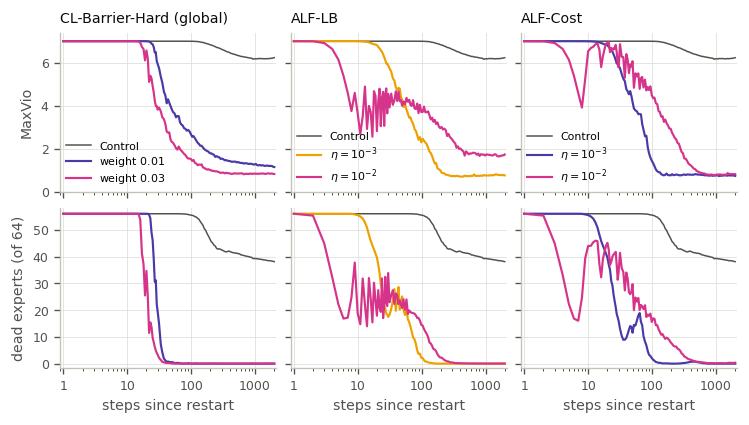

In [15]:
def log_bins(series, per_step_until=20, factor=1.05):
    """Means over bins that are single steps up to `per_step_until` and then log-spaced (each about 5 % of its step).
    Returns (mean step of the bin, mean value). A display device only: every number is computed on the raw series."""
    s = series.dropna()
    steps = s.index.to_numpy(dtype=float)
    edges = list(np.arange(0.5, per_step_until + 1.0))
    while edges[-1] < steps.max():
        edges.append(max(edges[-1] + 1.0, np.floor(edges[-1] * factor) + 0.5))
    g = pd.DataFrame({"b": np.digitize(steps, edges), "x": steps, "y": s.to_numpy()}).groupby("b")
    return g.x.mean().to_numpy(), g.y.mean().to_numpy()


def style_logx(ax, xmax=2000):
    ax.set_xscale("log")
    ax.set_xlim(0.9, xmax * 1.08)
    ticks = [t for t in (1, 10, 100, 1000) if t <= xmax]
    ax.set_xticks(ticks)
    ax.set_xticklabels([str(t) for t in ticks])
    ax.xaxis.set_minor_formatter(NullFormatter())


def race_line(ax, x, y, arm, lw=None, label=None, color=None, dash=None):
    """One race arm in its colour and dash (arm_style.race_meta), labelled with its name unless `label` is given;
    `color` and `dash` override the arm's own."""
    m = race_meta(arm)
    width = lw if lw is not None else (1.1 if arm == "control" else 1.3)
    return ax.plot(
        x,
        y,
        linestyle=dash or m["dash"],
        color=color or m["color"],
        lw=width,
        label=label or m["label"],
    )[0]


def step_bins(series, width):
    """Means over consecutive bins of `width` steps (1..width, width+1..2 width, ...): (mean step, mean value).
    A display device only: every number is computed on the raw series."""
    s = series.dropna()
    groups = s.groupby((s.index.to_numpy() - 1) // width)
    return groups.apply(lambda g: g.index.to_numpy().mean()).to_numpy(), groups.mean().to_numpy()


# The labelled steps of each axis scale, unless RACE_XTICKS overrides them.
RACE_DEFAULT_XTICKS = {
    "log": [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000],
    "sqrt": [0, 25, 50, 100, 200, 400, 800, 1200, 1600, 2000],
    "linear": list(range(0, 2001, 200)),
}


def style_race_x(ax, scale, xmax=2000):
    """Set the step axis of one race panel to `scale` ("log", "sqrt" or "linear")."""
    assert scale in RACE_DEFAULT_XTICKS, (
        f"RACE_XSCALE must be one of {list(RACE_DEFAULT_XTICKS)}, not {scale!r}"
    )
    if scale == "log":
        style_logx(ax, xmax)
        return
    if scale == "sqrt":
        ax.set_xscale("function", functions=(lambda x: np.sqrt(np.clip(x, 0, None)), np.square))
    ax.set_xlim(0, xmax * 1.01)
    ax.xaxis.set_minor_locator(NullLocator())


def race_curve(series, bins, width, smooth=1):
    """The drawn curve of one race series: RACE_BINS "fixed" (means over `width` steps) or "log" (log_bins), after
    an optional centred `smooth`-step mean that only the "log" averaging uses, for the loss panel."""
    assert bins in ("fixed", "log"), f"RACE_BINS must be 'fixed' or 'log', not {bins!r}"
    if bins == "log":
        if smooth > 1:
            series = series.rolling(smooth, center=True, min_periods=1).mean()
        return log_bins(series)
    return step_bins(series, width)


def fig_step125_race(scale=RACE_XSCALE, bins=RACE_BINS, width=RACE_BIN, xticks=RACE_XTICKS):
    """Three panels stacked over one shared, full-width step axis. Ticks along the bottom of (a) and (b) mark each
    arm's settle and revival step (T125, the table of the race)."""
    ctrl = R125["control"].lm_loss
    fig, axes = plt.subplots(3, 1, figsize=(6.3, 6.2), sharex=True)
    for arm in STEP125_CANONICAL:
        d = R125[arm]
        lw = (
            2.6 if arm == "switch_global" else None
        )  # Switch is drawn wide under its twin, the hard linear loss
        for ax, y in ((axes[0], d.maxvio), (axes[1], d.dead_experts)):
            race_line(ax, *race_curve(y, bins, width), arm, lw=lw)
        # paired difference to the control: every arm sees the same batches
        race_line(axes[2], *race_curve(d.lm_loss - ctrl, bins, width, smooth=15), arm, lw=lw)
        if arm != "control":
            color = race_meta(arm)["color"]
            for ax, key in ((axes[0], "settled"), (axes[1], "revived")):
                step = T125.loc[arm, key]
                if step is not None and not pd.isna(step):
                    ax.axvline(
                        float(step), ymin=0.0, ymax=0.05, color=color, lw=1.6, solid_capstyle="butt"
                    )
    axes[0].axhline(7.0, color=MUTED, lw=0.7, ls=":")
    axes[0].set_ylim(-0.35, 7.4)
    axes[0].set_ylabel("MaxVio")
    axes[0].set_title("(a) MaxVio; ticks: step at which the arm settles", loc="left", color=INK)
    axes[1].set_ylim(-3.0, 58)
    axes[1].set_ylabel("dead experts (of 64)")
    axes[1].set_title(
        "(b) dead experts; ticks: step from which the arm stays below one", loc="left", color=INK
    )
    axes[2].axhline(0.0, color=MUTED, lw=0.7, ls=":")
    axes[2].set_ylabel(r"$\Delta$ lm loss vs. control (nats)")
    axes[2].set_title("(c) training loss vs. control", loc="left", color=INK)
    for ax in axes:
        style_race_x(ax, scale)
        ax.axvline(HOLD_TO, color=MUTED, lw=0.6, ls="--")
    ticks = xticks or RACE_DEFAULT_XTICKS[scale]
    axes[2].set_xticks(ticks)
    axes[2].set_xticklabels([str(t) for t in ticks])
    axes[2].set_xlabel(
        {
            "sqrt": "steps since restart (square-root scale)",
            "log": "steps since restart (log scale)",
            "linear": "steps since restart",
        }[scale]
    )
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=4,
        bbox_to_anchor=(0.5, -0.005),
        handlelength=2.4,
        columnspacing=1.1,
        fontsize=6.9,
    )
    fig.tight_layout(rect=(0, 0.06, 1, 1), h_pad=0.9)
    save_figure(fig, "fig_step125_race")
    plt.show()


# The knob each variant turns, as its panel's legend names it: (base arm, variant).
VARIANT_KNOB = {
    "rosenthal_barrier_hard_global_coeff3e-2": ("weight $0.01$", "weight $0.03$"),
    "alflb_eta1e-2": (r"$\eta = 10^{-3}$", r"$\eta = 10^{-2}$"),
    "rosenthal_price_barrier_eta1e-2": (r"$\eta = 10^{-3}$", r"$\eta = 10^{-2}$"),
}


def fig_step125_variants():
    fig, axes = plt.subplots(2, 3, figsize=(6.3, 3.6), sharex=True, sharey="row")
    for j, variant in enumerate(STEP125_VARIANTS):
        base = RACE_BASE[variant]
        knob_base, knob_variant = VARIANT_KNOB[variant]
        for i, key in enumerate(("maxvio", "dead_experts")):
            ax = axes[i][j]
            race_line(ax, *log_bins(R125["control"][key]), "control", lw=0.9)
            race_line(ax, *log_bins(R125[base][key]), base, label=knob_base, dash=VARIANT_BASE_DASH)
            race_line(
                ax,
                *log_bins(R125[variant][key]),
                variant,
                label=knob_variant,
                color=VARIANT_COLOR,
                dash=VARIANT_DASH,
            )
            style_logx(ax)
            if i == 0:
                ax.set_title(race_meta(base)["label"], loc="left", color=INK, fontsize=8.5)
                ax.set_ylim(0, 7.4)
                # low in the panel, below the oscillation of ALF-LB at the larger step size
                ax.legend(
                    loc="lower left",
                    fontsize=6.6,
                    handlelength=2.2,
                    borderaxespad=0.15,
                    labelspacing=0.3,
                )
            else:
                ax.set_ylim(-1.5, 58)
                ax.set_xlabel("steps since restart")
    axes[0][0].set_ylabel("MaxVio")
    axes[1][0].set_ylabel("dead experts (of 64)")
    fig.tight_layout(h_pad=0.6, w_pad=0.6)
    save_figure(fig, "fig_step125_variants")
    plt.show()


if wanted("fig_step125_race"):
    fig_step125_race()
if wanted("fig_step125_variants"):
    fig_step125_variants()

---
## The race from step 150 (logs; the figure `fig_app_revival_probes` follows in the next section)

An earlier race with four arms started from the final, annealed checkpoint of the negative-auxiliary-loss induction at step 150 and ran 4000 steps on 16 GPUs. It is not exported, so its numbers come from the training logs, which print every tenth step (MaxVio and dead experts of the printed step, two decimals). Its definitions follow the race from step 125, on the logged steps: the revival must hold at every logged step until the anneal starts at step 3800, and the plateau is the mean over the logged steps 1010..3800. The price-barrier arm is its clean rerun (`-r2`); `STEP150_JOBS` names the jobs.

In [16]:
ANNEAL_150 = 3800
rows = {}
for job, arm in STEP150_JOBS.items():
    lines = LOG_LINES[job]
    de, mv = lines.dead_experts, lines.maxvio
    rows[arm] = {
        "job": job,
        "run": LOG_INFO.wandb_exp_name[job],
        "last": int(lines.index.max()),
        "dead<1 first": first_step(de < 1),
        "revived": first_held(de, lambda v: v < 1, ANNEAL_150),
        "MaxVio<2 first": first_step(mv < 2),
        "MaxVio<1 first": first_step(mv < 1),
        "MaxVio 1010-3800": mv.loc[1010:ANNEAL_150].mean(),
        "dead 1010-3800": de.loc[1010:ANNEAL_150].mean(),
    }
T150 = pd.DataFrame(rows).T
print(T150.to_string())
job = next(iter(STEP150_JOBS))
S = "race from step 150 (logs)"
note(
    S,
    "configuration (logs)",
    f"{LOG_INFO.world_size[job]} GPUs, global batch {LOG_INFO.global_batch_size[job]}, "
    f"{LOG_INFO.train_iters[job]} steps, every {LOG_INFO.log_interval[job]}th step logged",
)
for arm, r in T150.iterrows():
    note(
        S,
        f"table row, {arm} (job {r.job})",
        f"dead<1 first {r['dead<1 first'] or '---'}, revived {r.revived or '---'}, "
        f"MaxVio 1010-3800 {r['MaxVio 1010-3800']:.3f}, dead 1010-3800 {r['dead 1010-3800']:.3f}",
    )
note(
    S,
    "softplus barrier plateau here vs in the race from step 125",
    f"{T150.loc['rosenthal_barrier_hard_global', 'MaxVio 1010-3800']:.3f} vs {T125.loc['rosenthal_barrier_hard_global', 'plateau']:.3f}",
)

                                   job                                                        run  last dead<1 first revived MaxVio<2 first MaxVio<1 first MaxVio 1010-3800 dead 1010-3800
control                        3392692                                     control-negaux-control  4000         None    None           None           None         6.244857      37.368714
alflb                          3392693                                         alflb-negaux-alflb  4000          110     110            140            220         0.785036       0.006321
rosenthal_barrier_hard_global  3392695       rosenthal_barrier_hard-negaux-rosenthal-barrier-hard  4000           50      50            900           None         1.925679       0.082107
rosenthal_price_barrier        3393836  rosenthal_price_barrier-negaux-rosenthal-price-barrier-r2  4000          130     130             90            130         0.771929       0.002714


---
## How the dead experts come back: probe dumps of the race from step 150 (`fig_app_revival_probes`)

A bias arm adds its bias to the router's scores before the top-K, so it can send tokens to an expert whose score is still close to zero. Such an expert is selected, but its gate, the normalized score that scales its output and with it its gradient, stays close to zero. A loss arm can only raise the scores themselves. The probe dumps of the race from step 150 show which of the two happens. They are summarized in `assets/results/revival-probes/` by `scripts/summarize_revival_probes.py`: per arm, probe step (every 25 steps up to 500) and MoE layer, on the probe unit of the strided asset. The step-125 race's dumps no longer exist, but its bias arms stall in the same way (its section above), so this race stands in for it.

- **Formerly dead:** the experts without a token on the probe unit at the race's step 0 (50 to 56 per layer).
- **Selection share and gate share:** the share of the token's K selections, and of its gate weight (which sums to one per token), that go to those experts; means over the 8 layers.
- **Dead experts per micro batch:** on the probe unit, counted per micro batch of 8,192 tokens as training counts them. The probe unit draws its tokens from many documents, so these counts are lower than in training. The figure shows only the selections and the gate weight; the stall and the loss excess of this race are noted from its training logs (every tenth step).
- **Bias range and score spread:** of the formerly dead experts, the range of their biases and the mean over tokens of the range of their scores. While the score spread is below the bias range, the bias, not the token, decides which of them a token selects.


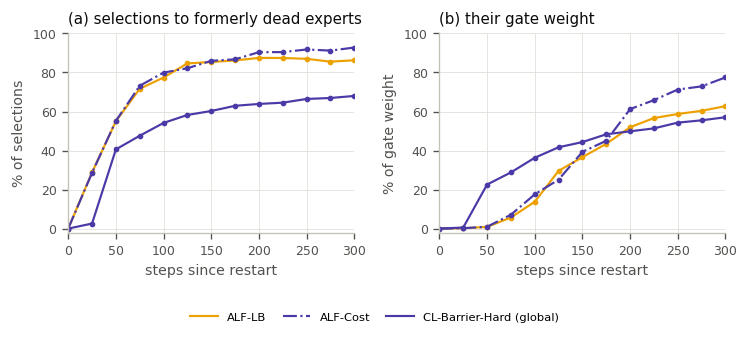

In [17]:
REVIVAL_ARMS = ["alflb", "rosenthal_price_barrier", "rosenthal_barrier_hard_global"]


def fig_app_revival_probes(probes, xmax=300):
    """(a) selection share and (b) gate share of the formerly dead experts on the probe unit, per probe step."""
    fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.75), sharex=True)
    by_step = (
        probes[probes.step <= xmax]
        .groupby(["arm", "step"])[["selection_share", "gate_share"]]
        .mean()
    )
    for arm in REVIVAL_ARMS:
        d = by_step.loc[arm]
        for ax, y in ((axes[0], 100 * d.selection_share), (axes[1], 100 * d.gate_share)):
            race_line(ax, d.index, y, arm)
            ax.plot(d.index, y, "o", ms=2.4, color=race_meta(arm)["color"])
    axes[0].set_ylabel("% of selections")
    axes[0].set_title("(a) selections to formerly dead experts", loc="left", color=INK)
    axes[1].set_ylabel("% of gate weight")
    axes[1].set_title("(b) their gate weight", loc="left", color=INK)
    for ax in axes:
        ax.set_xlabel("steps since restart")
        ax.set_xlim(0, xmax)
        ax.set_xticks(range(0, xmax + 1, 50))
        ax.set_ylim(-2, 100)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=3,
        bbox_to_anchor=(0.5, -0.02),
        handlelength=2.4,
        columnspacing=1.4,
        fontsize=6.9,
    )
    fig.tight_layout(rect=(0, 0.1, 1, 1), w_pad=1.2)
    save_figure(fig, "fig_app_revival_probes")
    plt.show()


if REVIVAL_PROBES.is_file():
    PROBES150 = pd.read_csv(REVIVAL_PROBES)
    assert set(REVIVAL_ARMS) <= set(PROBES150.arm), sorted(PROBES150.arm.unique())
    assert (PROBES150.groupby(["arm", "step"]).layer.count() == 8).all(), (
        "every dump must have its 8 layers"
    )
    m = PROBES150.groupby(["arm", "step"]).mean(numeric_only=True)
    S = "race from step 150, probe dumps"
    note(
        S,
        "source",
        f"{REVIVAL_PROBES.relative_to(ROOT)}, {len(PROBES150)} rows, steps "
        f"{PROBES150.step.min()}..{PROBES150.step.max()}, asset {PROBES150.asset.iloc[0]}; formerly dead per layer "
        f"{PROBES150.formerly_dead.min()}..{PROBES150.formerly_dead.max()}",
    )
    for arm in REVIVAL_ARMS:
        a = m.loc[arm]
        note(
            S,
            f"{arm}: selection share / gate share (%) at steps 25, 50, 75, 100",
            "; ".join(
                f"{s}: {100 * a.selection_share[s]:.1f} / {100 * a.gate_share[s]:.2f}"
                for s in (25, 50, 75, 100)
            ),
        )
        note(
            S,
            f"{arm}: gate per selection, formerly dead / survivors, step 25",
            f"{a.gate_per_selection_formerly_dead[25]:.4f} / {a.gate_per_selection_survivors[25]:.4f}",
        )
        note(
            S,
            f"{arm}: dead experts per micro batch on the probe unit at steps 25, 50, 75, 100",
            ", ".join(f"{a.dead_per_micro_batch[s]:.2f}" for s in (25, 50, 75, 100)),
        )
        note(
            S,
            f"{arm}: bias range / score spread of the formerly dead experts at steps 25, 50, 75, 100",
            "; ".join(
                f"{s}: {a.bias_range_formerly_dead[s]:.4f} / {a.score_spread_formerly_dead[s]:.4f}"
                for s in (25, 50, 75, 100)
            ),
        )
        note(
            S,
            f"{arm}: their score on the tokens that select them, step 25",
            f"{a.score_on_own_tokens_formerly_dead[25]:.4f}",
        )
    bias = [a for a in REVIVAL_ARMS if a in BIAS_ARMS]
    note(
        S,
        "bias arms: largest bias range of the formerly dead experts, steps 25..50",
        f"{m.loc[bias].query('25 <= step <= 50').bias_range_formerly_dead.max():.4f}",
    )
    # the stall and the loss excess in the same race, from its logs (every tenth step)
    logs = {arm: LOG_LINES[job] for job, arm in STEP150_JOBS.items()}
    for arm in bias:
        de = logs[arm].dead_experts.loc[:120]
        low = de.loc[20:50].idxmin()
        high = de.loc[low:90].idxmax()
        excess = (logs[arm]["lm loss"] - logs["control"]["lm loss"]).loc[:300]
        first = excess[(excess > 0.01) & (excess.index >= 60)].index.min()
        note(
            S,
            f"{arm}: logged dead experts fall to, rise again to; loss - control first above +0.01 (from step 60), peak",
            f"{de[low]:.2f} at {low}, {de[high]:.2f} at {high}; {first}; {excess.max():+.3f} at {excess.idxmax()}",
        )
    if wanted("fig_app_revival_probes"):
        fig_app_revival_probes(PROBES150)
else:
    print(
        f"{REVIVAL_PROBES.relative_to(ROOT)} is missing: no fig_app_revival_probes "
        "(write it with scripts/summarize_revival_probes.py from the race's probe dumps)"
    )

---
## The race from the negative z-loss checkpoint (`fig_zloss_race`)

An earlier race started from step 500 of the sigmoid negative z-loss induction and ran 4000 steps on 16 GPUs: the control, ALF-LB and eight loss arms (all at the global-batch scope but one linear hard arm at the micro-batch scope). Three further runs from the same checkpoint are the **softmax carriers**: the Switch loss and the hard softplus-barrier loss computed on the softmax of the logits, while the router still selects on sigmoid scores, and one Switch carrier with the z-loss weight raised to $10^{-2}$. A saturated sigmoid passes almost no gradient to the scores, so the carriers test whether the loss arms fail because the sigmoid blocks them. Their export holds MaxVio and the dead experts only; their loss is read from their logs where quoted (every tenth line, a mean over ten steps).

Two runs end early: the linear soft arm at step 250 and the Switch arm at step 3118. Their "last 100 steps" are therefore not the end of the race. The table's columns: the length of the run; the lowest trailing 25-step mean of the dead experts, with the last of those steps; and the means over the last 100 steps of the run.

                                           job last step lowest dead (25) at step dead last 100 MaxVio last 100 ever dead < 1 ever MaxVio < 2 loss last 100 loss step 9 loss step 10 lowest loss after step 10 median grad norm largest grad norm
switch_global                          3333772      3118            37.83    1217         53.72               7         False           False          15.2       7.485        16.63                     7.405        4.391e+05         1.191e+17
rosenthal_linear_hard_global           3333753      4000            39.03    1707         51.16               7         False           False         14.22       7.485        16.62                     7.311        2.459e+06         1.283e+14
rosenthal_linear_hard_micro            3333754      4000            35.64     262         54.67               7         False           False         7.578       7.483        16.63                     7.377        4.698e+04         7.026e+15
rosenthal_linear_soft_global    

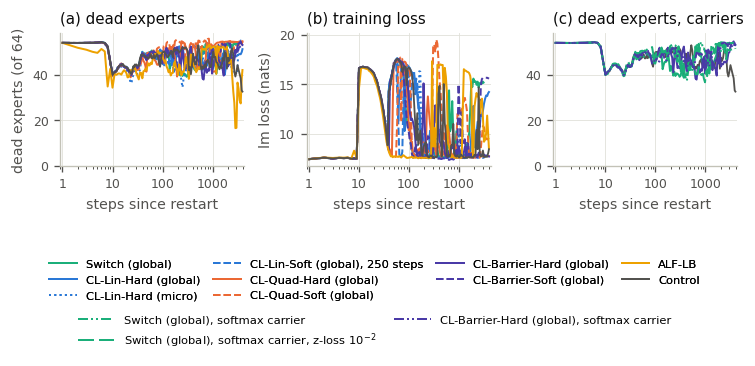

In [18]:
zruns = {run: frame for prefix in ZLOSS_EXPORTS for run, frame in EXPORTS[prefix].items()}
assert set(zruns) == set(ZLOSS_RUNS), set(zruns) ^ set(ZLOSS_RUNS)
assert all((CHECK[CHECK.export == p].verdict == "pass").all() for p in ZLOSS_EXPORTS), (
    "a z-loss race run failed the check"
)
RZ = {ZLOSS_RUNS[run]: frame for run, frame in zruns.items()}
RZ_JOB = {
    ZLOSS_RUNS[run]: CHECK[(CHECK.run == run) & CHECK.export.isin(ZLOSS_EXPORTS)][
        "checked against"
    ].iloc[0]
    for run in zruns
}

rows = {}
for arm in ZLOSS_ARMS + ZLOSS_CARRIERS:
    d = RZ[arm]
    dead25 = trailing(d.dead_experts)
    r = {
        "job": RZ_JOB[arm],
        "last step": int(d.index.max()),
        "lowest dead (25)": dead25.min(),
        "at step": int(dead25.idxmin()),
        "dead last 100": d.dead_experts.iloc[-100:].mean(),
        "MaxVio last 100": d.maxvio.iloc[-100:].mean(),
        "ever dead < 1": bool((d.dead_experts < 1).any()),
        "ever MaxVio < 2": bool((d.maxvio < 2).any()),
    }
    if "lm_loss" in d:
        r.update(
            {
                "loss last 100": d.lm_loss.iloc[-100:].mean(),
                "loss step 9": d.lm_loss.loc[9],
                "loss step 10": d.lm_loss.loc[10],
                "lowest loss after step 10": d.lm_loss.loc[11:].min(),
                "median grad norm": d.grad_norm.median(),
                "largest grad norm": d.grad_norm.max(),
            }
        )
    rows[arm] = r
TZ = pd.DataFrame(rows).T
with pd.option_context("display.width", 250, "display.max_columns", 30):
    print(TZ.to_string(float_format=lambda v: f"{v:.4g}"))

S = "race from the negative z-loss checkpoint"
first = pd.DataFrame({a: RZ[a].loc[1] for a in RZ}).T
note(
    S,
    "step 1, every run (13)",
    f"dead {first.dead_experts.min():.3f}..{first.dead_experts.max():.3f}, MaxVio {first.maxvio.min():.2f}..{first.maxvio.max():.2f}, "
    f"loss {first.lm_loss.min():.4f}..{first.lm_loss.max():.4f}",
)
job = RZ_JOB["control"]
note(
    S,
    "configuration (logs)",
    f"{LOG_INFO.world_size[job]} GPUs, global batch {LOG_INFO.global_batch_size[job]}, seed {LOG_INFO.seed[job]}, "
    f"{LOG_INFO.train_iters[job]} steps, z-loss weight {LOG_INFO.moe_z_loss_coeff[job]}",
)
for arm in ZLOSS_ARMS:
    r = TZ.loc[arm]
    note(
        S,
        f"table row, {arm}",
        f"steps {r['last step']}, lowest dead {r['lowest dead (25)']:.1f} ({r['at step']}), dead last 100 "
        f"{r['dead last 100']:.2f}, MaxVio last 100 {r['MaxVio last 100']:.2f}, loss last 100 {r['loss last 100']:.2f}",
    )
note(S, "any arm ever below one dead expert", bool(TZ["ever dead < 1"].any()))
full = [a for a in ZLOSS_ARMS if TZ.loc[a, "last step"] == 4000]
loss_full = [a for a in full if a not in ("control", "alflb")]
note(
    S,
    "dead, last 100 steps: control / ALF-LB / loss arms that reach step 4000",
    f"{TZ.loc['control', 'dead last 100']:.2f} / {TZ.loc['alflb', 'dead last 100']:.2f} / "
    f"{TZ.loc[loss_full, 'dead last 100'].min():.2f}..{TZ.loc[loss_full, 'dead last 100'].max():.2f}",
)
note(
    S,
    "the control has the fewest dead experts over the last 100 steps",
    TZ.loc[full, "dead last 100"].idxmin() == "control",
)
note(
    S,
    "dead at step 4000: control / ALF-LB / loss arms",
    f"{RZ['control'].dead_experts.loc[4000]:.2f} / {RZ['alflb'].dead_experts.loc[4000]:.2f} / "
    f"{min(RZ[a].dead_experts.loc[4000] for a in loss_full):.2f}..{max(RZ[a].dead_experts.loc[4000] for a in loss_full):.2f}",
)
note(
    S,
    "loss at step 9 and at step 10, range over the 10 arms",
    f"{TZ.loc[ZLOSS_ARMS, 'loss step 9'].min():.2f}..{TZ.loc[ZLOSS_ARMS, 'loss step 9'].max():.2f}; "
    f"{TZ.loc[ZLOSS_ARMS, 'loss step 10'].min():.2f}..{TZ.loc[ZLOSS_ARMS, 'loss step 10'].max():.2f}",
)
note(
    S,
    "lowest loss after step 10, any arm",
    f"{TZ.loc[ZLOSS_ARMS, 'lowest loss after step 10'].min():.2f}",
)
note(
    S,
    "median grad norm per arm, range; largest grad norm",
    f"{TZ.loc[ZLOSS_ARMS, 'median grad norm'].min():.3g}..{TZ.loc[ZLOSS_ARMS, 'median grad norm'].max():.3g}; "
    f"{TZ.loc[ZLOSS_ARMS, 'largest grad norm'].max():.3g}",
)
zl = pd.DataFrame({a: LOG_LINES[RZ_JOB[a]].z_loss.loc[[1, 20]] for a in RZ}).T
note(
    S,
    "logged z-loss before its weight, line of step 1 and of step 20 (mean of steps 11..20), 13 runs",
    f"{zl[1].min():.0f}..{zl[1].max():.0f}; {zl[20].min():.2f}..{zl[20].max():.2f}",
)
note(
    S,
    "runs that end early",
    ", ".join(
        f"{a} at {TZ.loc[a, 'last step']}" for a in ZLOSS_ARMS if TZ.loc[a, "last step"] < 4000
    ),
)
S = "race from the negative z-loss checkpoint, softmax carriers"
# The carriers' loss is not exported. Their logs print a ten-step mean every tenth step, so the mean of the last ten
# lines is the mean over the last 100 steps; checked here on the ten arms, whose loss is exported.
tail = {
    a: (LOG_LINES[RZ_JOB[a]]["lm loss"].loc[3910:4000].mean(), RZ[a].lm_loss.loc[3901:4000].mean())
    for a in ZLOSS_ARMS
    if TZ.loc[a, "last step"] == 4000
}
worst = max(abs(x / y - 1) for x, y in tail.values())
note(
    S,
    "mean of the last 10 log lines vs the exported mean over the last 100 steps, arms that reach step 4000",
    f"largest relative difference {worst:.1e} over {len(tail)} arms",
)
assert worst < 1e-5
for arm in ZLOSS_CARRIERS:
    r, job = TZ.loc[arm], RZ_JOB[arm]
    lines = LOG_LINES[job]
    note(
        S,
        f"{arm} (job {job}; base {RACE_BASE[arm]})",
        f"steps {r['last step']}, lowest dead {r['lowest dead (25)']:.1f} ({r['at step']}), "
        f"dead last 100 {r['dead last 100']:.2f}, MaxVio last 100 {r['MaxVio last 100']:.2f}, ever dead < 1 {r['ever dead < 1']}; "
        f"aux score function {LOG_INFO.moe_router_aux_score_function[job]}, z-loss weight {LOG_INFO.moe_z_loss_coeff[job]}; "
        f"logged loss: line of step 20 {lines['lm loss'].loc[20]:.2f}, lowest line after 20 {lines['lm loss'].loc[21:].min():.2f}, "
        f"over the last 100 steps (last 10 lines) {lines['lm loss'].loc[3910:4000].mean():.2f}",
    )
for arm in ZLOSS_CARRIERS:
    base = RACE_BASE[arm]
    note(
        S,
        f"{arm} vs its base arm {base}",
        f"lowest dead {TZ.loc[arm, 'lowest dead (25)']:.1f} vs {TZ.loc[base, 'lowest dead (25)']:.1f}; "
        f"dead last 100 {TZ.loc[arm, 'dead last 100']:.2f} vs {TZ.loc[base, 'dead last 100']:.2f}",
    )


def fig_zloss_race():
    ncols = 3 if ZLOSS_CARRIER_PANEL else 2
    fig, axes = plt.subplots(1, ncols, figsize=(6.3, 2.5 if ncols == 2 else 3.0))
    for arm in ZLOSS_ARMS:
        label = race_meta(arm)["label"] + (
            f", {TZ.loc[arm, 'last step']} steps" if TZ.loc[arm, "last step"] < 1000 else ""
        )
        race_line(
            axes[0],
            *log_bins(RZ[arm].dead_experts),
            arm,
            lw=1.2 if arm != "control" else 1.1,
            label=label,
        )
        race_line(
            axes[1],
            *log_bins(RZ[arm].lm_loss),
            arm,
            lw=1.2 if arm != "control" else 1.1,
            label=label,
        )
    axes[0].set_ylim(0, 58)
    axes[0].set_ylabel("dead experts (of 64)")
    axes[0].set_title("(a) dead experts", loc="left", color=INK)
    axes[1].set_ylabel("lm loss (nats)")
    axes[1].set_title("(b) training loss", loc="left", color=INK)
    if ZLOSS_CARRIER_PANEL:
        # Each carrier against the arm it changes (sigmoid scores for the loss) and the control.
        bases = sorted({RACE_BASE[a] for a in ZLOSS_CARRIERS}, key=ZLOSS_ARMS.index)
        for arm in ["control"] + bases + ZLOSS_CARRIERS:
            race_line(
                axes[2], *log_bins(RZ[arm].dead_experts), arm, lw=1.2 if arm != "control" else 1.1
            )
        axes[2].set_ylim(0, 58)
        axes[2].set_title("(c) dead experts, carriers", loc="left", color=INK)
    for ax in axes:
        style_logx(ax, 4000)
        ax.set_xlabel("steps since restart")
    handles, labels = axes[0].get_legend_handles_labels()
    if not ZLOSS_CARRIER_PANEL:
        fig.legend(
            handles,
            labels,
            loc="lower center",
            ncol=3,
            bbox_to_anchor=(0.5, -0.02),
            handlelength=2.4,
            columnspacing=1.1,
            fontsize=6.9,
        )
        fig.tight_layout(rect=(0, 0.2, 1, 1), w_pad=1.2)
    else:
        # Two legends: the ten race arms, and below them the three carriers (their base arms are in the first).
        first = fig.legend(
            handles,
            labels,
            loc="lower center",
            ncol=4,
            bbox_to_anchor=(0.5, 0.125),
            handlelength=2.4,
            columnspacing=1.1,
            fontsize=6.9,
        )
        fig.add_artist(first)
        handles = [
            Line2D([], [], color=race_meta(a)["color"], ls=race_meta(a)["dash"], lw=1.2)
            for a in ZLOSS_CARRIERS
        ]
        fig.legend(
            handles,
            [race_meta(a)["label"] for a in ZLOSS_CARRIERS],
            loc="lower center",
            ncol=2,
            bbox_to_anchor=(0.5, -0.01),
            handlelength=3.2,
            columnspacing=1.6,
            fontsize=6.9,
        )
        fig.tight_layout(rect=(0, 0.36, 1, 1), w_pad=1.0)
    save_figure(fig, "fig_zloss_race")
    plt.show()


if wanted("fig_zloss_race"):
    fig_zloss_race()

---
## Every number the text quotes

The figures and the spike table are written above. This cell collects the numbers the running text and the hand-written tables quote, grouped by the section that computes them, in the order of this notebook and with more decimals than the thesis uses. A range "a..b" is the smallest and the largest value over the arms or events named; a percentage change is `100 * (new / old - 1)`; "train / probe" is the training-batch value divided by the probe value. The check rows at the top say which exports were verified against the logs.

In [19]:
# In the order of this notebook: NUMBERS keeps the order in which its topics were first noted.
for section in NUMBERS:
    print(f"[{section}]")
    for name, value in NUMBERS[section].items():
        print(f"  {name}: {value}")
    print()
print(
    f"written to {OUT_DIR.relative_to(ROOT)}/",
    f"and to {THESIS_DIR}/"
    if THESIS_DIR
    else "(set THESIS_DIR to copy them into the thesis as well)",
)
for name in WRITTEN:
    print(" ", name)
not_written = [
    name
    for name in OUTPUTS
    if wanted(name)
    and not any(w.endswith(f"/{name}.pdf") or w.endswith(f"/{name}.tex") for w in WRITTEN)
]
assert not not_written, f"asked for but not written: {not_written}"

[check]
  dead experts on the averaging grid: 11B/wandb_11B 1/2048: 76999/76999 steps, collapse-induce/wandb_induce_negaux 1/256: 150/150 steps, collapse-induce/wandb_induce_sigmoid 1/256: 1000/1000 steps, recovery-null/wandb_recovery_null 1/256: 35368/35368 steps, recovery-null/wandb_softmax_carrier 1/256: 12000/12000 steps, recovery/wandb_step125 1/256: 20000/20000 steps
  exports checked against a log at every logged step: 33 pass, 1 mislabelled, 0 fail, 5 without a log (of 39 runs)
  11B/wandb_11B / quadratic, soft: no log in the repository
  11B/wandb_11B / linear, hard: no log in the repository
  11B/wandb_11B / ALF-LB: no log in the repository
  11B/wandb_11B / quadratic, hard: no log in the repository
  11B/wandb_11B / Control: no log in the repository
  collapse-induce/wandb_induce_sigmoid / induce_sigmoid-collapse: MISLABELLED: its name is the run of job 3315605, its values are job 3309238

[validation loss]
  check against the logs: 9 arms with logs, max |export - log| 4.9e-